## Rollout an RGM decoder from a neutral pose

Loads a `distill_prior` checkpoint, initializes the rodent in the model's neutral
`qpos0` pose, and rolls the RGM decoder loop forward for `ROLLOUT_NUM_STEPS`
timesteps at `fixed_logvar = -3`. The resulting qpos trajectory is rendered
using the same helper as above.

In [1]:
import os

os.environ.setdefault("MUJOCO_GL", "egl")
os.environ.setdefault("PYOPENGL_PLATFORM", "egl")

# ============ EDIT THESE ============
DISTILL_PRIOR_CHECKPOINT = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/distill_prior_checkpoints/260406_130524_381481"
DISTILL_PRIOR_STEP = 54  # None = latest
ROLLOUT_NUM_STEPS = 1000
ROLLOUT_LOGVAR = -4.0
ROLLOUT_SEEDS = [
    0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15,
    16,
    17,
]  # one rollout per seed

# ============ RENDER SETTINGS ============
ROLLOUT_CAMERA_NAME = "close_profile-rodent"
ROLLOUT_RENDER_HEIGHT = 720
ROLLOUT_RENDER_WIDTH = 1280
ROLLOUT_RENDER_FPS = 50

# Render model: match the rollout env (no-tail-collisions rodent, rescale 0.9).
from scamper.environment.rodent import consts as _rodent_consts

ROLLOUT_WALKER_XML = str(_rodent_consts.RODENT_NO_TAIL_COLLISION_XML)
ROLLOUT_ARENA_XML = str(_rodent_consts.ARENA_XML_PATH)
ROLLOUT_RESCALE_FACTOR = 0.9

In [2]:
import jax
import jax.numpy as jnp
from jax import random
from mujoco import mjx
from omegaconf import OmegaConf

from scamper.environment.rodent import consts as rodent_consts
from scamper.scripts.collect_rollout_dataset_distill import (
    load_distill_prior_checkpoint_for_rollouts,
    create_rgm_policy_fn,
)
from scamper.scripts.collect_rollout_dataset import (
    fix_config_paths,
    create_environment,
)
from scamper.agent.observation_utils import flatten_obs_dict

cfg, policy_params = load_distill_prior_checkpoint_for_rollouts(
    DISTILL_PRIOR_CHECKPOINT, DISTILL_PRIOR_STEP
)

# Override backend to warp and swap in the no-tail-collisions rodent.
OmegaConf.set_struct(cfg.env_config, False)
print(f"  mujoco_impl: {cfg.env_config.mujoco_impl} -> warp")
OmegaConf.update(cfg.env_config, "mujoco_impl", "warp")
new_xml_path = str(rodent_consts.RODENT_NO_TAIL_COLLISION_XML)
print(
    f"  walker_xml_path: {cfg.env_config.get('walker_xml_path', 'N/A')} -> {new_xml_path}"
)
OmegaConf.update(cfg.env_config, "walker_xml_path", new_xml_path)
OmegaConf.set_struct(cfg.env_config, True)

cfg = fix_config_paths(cfg)
rollout_env, _reference_clips = create_environment(cfg)
print(
    f"Loaded distill_prior checkpoint from {DISTILL_PRIOR_CHECKPOINT} step {DISTILL_PRIOR_STEP}"
)

Loading distill_prior checkpoint from /home/mila/a/aidan.sirbu/SCAMPER/scratch/distill_prior_checkpoints/260406_130524_381481 at step 54
  mujoco_impl: jax -> warp
  walker_xml_path: /tmp/SCAMPER/scamper/environment/rodent/xmls/rodent.xml -> /home/mila/a/aidan.sirbu/SCAMPER/scamper/environment/rodent/xmls/rodent_no_tail_collisions.xml
Warp 1.11.0 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "NVIDIA L40S" (45 GiB, sm_89, mempool enabled)
   Kernel cache:
     /home/mila/a/aidan.sirbu/.cache/warp/1.11.0
Warp DeprecationWarning: The symbol `warp.types.warp_type_to_np_dtype` will soon be removed from the public API. It can still be accessed from `warp._src.types.warp_type_to_np_dtype` but might be changed or removed without notice.
Loaded distill_prior checkpoint from /home/mila/a/aidan.sirbu/SCAMPER/scratch/distill_prior_checkpoints/260406_130524_381481 step 54


In [3]:
import mujoco
import numpy as np

from scamper.environment.utils import dm_scale_spec


def build_rollout_render_model():
    arena = mujoco.MjSpec.from_file(ROLLOUT_ARENA_XML)
    rodent = mujoco.MjSpec.from_file(ROLLOUT_WALKER_XML)
    if ROLLOUT_RESCALE_FACTOR != 1.0:
        rodent = dm_scale_spec(rodent, ROLLOUT_RESCALE_FACTOR)
    frame = arena.worldbody.add_frame(pos=(0, 0, 0), quat=(1, 0, 0, 0))
    body = frame.attach_body(rodent.body("walker"), "", suffix="-rodent")
    body.add_freejoint(name="root")
    model = arena.compile()
    model.vis.global_.offwidth = max(model.vis.global_.offwidth, ROLLOUT_RENDER_WIDTH)
    model.vis.global_.offheight = max(
        model.vis.global_.offheight, ROLLOUT_RENDER_HEIGHT
    )
    return model


rollout_render_model = build_rollout_render_model()
rollout_render_data = mujoco.MjData(rollout_render_model)
print(f"render model nq={rollout_render_model.nq}, nv={rollout_render_model.nv}")

_rollout_cam_id = mujoco.mj_name2id(
    rollout_render_model, mujoco.mjtObj.mjOBJ_CAMERA, ROLLOUT_CAMERA_NAME
)
if _rollout_cam_id < 0:
    print(
        f"warning: camera {ROLLOUT_CAMERA_NAME!r} not found; using default free camera"
    )
    rollout_cam_arg = None
else:
    rollout_cam_arg = _rollout_cam_id


def render_rollout_qpos(qpos_traj):
    renderer = mujoco.Renderer(
        rollout_render_model,
        height=ROLLOUT_RENDER_HEIGHT,
        width=ROLLOUT_RENDER_WIDTH,
    )
    frames = []
    try:
        for t in range(qpos_traj.shape[0]):
            rollout_render_data.qpos[:] = qpos_traj[t]
            mujoco.mj_forward(rollout_render_model, rollout_render_data)
            if rollout_cam_arg is None:
                renderer.update_scene(rollout_render_data)
            else:
                renderer.update_scene(rollout_render_data, camera=rollout_cam_arg)
            frames.append(renderer.render().copy())
    finally:
        renderer.close()
    return frames

render model nq=74, nv=73


In [4]:
def create_neutral_state(env, rng_key):
    """Initialize env state with the model's neutral qpos0 (z=0) and zero qvel."""
    state = env.reset(rng_key)
    mjx_model = env.mjx_model
    neutral_qpos = jnp.array(env.mj_model.qpos0)
    neutral_qpos = neutral_qpos.at[2].set(0)
    data = state.data.replace(qpos=neutral_qpos, qvel=jnp.zeros(mjx_model.nv))
    data = mjx.forward(mjx_model, data)
    return state.replace(data=data)


def run_single_rollout(env, policy_fn, starting_state, num_steps, rng_key):
    jit_step = jax.jit(env.step)

    def step_fn(carry, _):
        state, key = carry
        key, action_key = random.split(key)
        if isinstance(state.obs, dict) or hasattr(state.obs, "get"):
            proprio = flatten_obs_dict(state.obs)["proprioception"]
        else:
            proprio = state.obs
        action, _ = policy_fn(proprio, action_key)
        next_state = jit_step(state, action)
        return (next_state, key), next_state

    (_final_state, _), all_states = jax.lax.scan(
        step_fn, (starting_state, rng_key), None, length=num_steps
    )
    jax.tree_util.tree_map(lambda x: x.block_until_ready(), all_states)
    return all_states


rgm_policy = create_rgm_policy_fn(
    policy_params, cfg, fixed_logvar=ROLLOUT_LOGVAR, deterministic=False
)

rollout_qpos_by_seed = {}
for seed in ROLLOUT_SEEDS:
    rng = random.PRNGKey(seed)
    rng_init, rng_rollout = random.split(rng)
    starting_state = create_neutral_state(rollout_env, rng_init)
    all_states = run_single_rollout(
        rollout_env, rgm_policy, starting_state, ROLLOUT_NUM_STEPS, rng_rollout
    )
    rollout_qpos_by_seed[seed] = np.asarray(all_states.data.qpos)
    print(f"seed={seed}: qpos shape={rollout_qpos_by_seed[seed].shape}")

Module mujoco.mjx.third_party.mujoco_warp._src.smooth e142b0f load on device 'cuda:0' took 17.11 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.collision_driver de6dc98 load on device 'cuda:0' took 4.99 ms  (cached)
Module _nxn_broadphase__locals__kernel_8c837afb 8c837af load on device 'cuda:0' took 4.97 ms  (cached)
Module _primitive_narrowphase__locals__primitive_narrowphase_3a95495c 42367f3 load on device 'cuda:0' took 5.74 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.constraint 51cd7b3 load on device 'cuda:0' took 9.28 ms  (cached)
Module _actuator_velocity__locals__actuator_velocity_0d638ad6 1622c88 load on device 'cuda:0' took 4.94 ms  (cached)
Module _tendon_velocity__locals__tendon_velocity_72b33c1e d7da02d load on device 'cuda:0' took 4.87 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.passive 6808b5e load on device 'cuda:0' took 6.18 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.sensor ca6ca3f load on device 'cuda:0' took

### Save rollouts to an .h5 file

Writes `rollout_qpos_by_seed` to `Plots/rollouts/rollouts_{run_id}_step{step}_logvar{logvar}_steps{num_steps}.h5`
so the rollouts can be reloaded later without regenerating them.


In [5]:
import h5py
from pathlib import Path

ROLLOUT_SAVE_DIR = Path(
    "/home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/rollouts"
)
ROLLOUT_SAVE_DIR.mkdir(parents=True, exist_ok=True)

_run_id = Path(DISTILL_PRIOR_CHECKPOINT).name
rollout_save_path = (
    ROLLOUT_SAVE_DIR
    / f"rollouts_{_run_id}_step{DISTILL_PRIOR_STEP}_logvar{ROLLOUT_LOGVAR:g}_steps{ROLLOUT_NUM_STEPS}.h5"
)

with h5py.File(rollout_save_path, "w") as _f:
    _f.attrs["checkpoint"] = DISTILL_PRIOR_CHECKPOINT
    _f.attrs["step"] = DISTILL_PRIOR_STEP
    _f.attrs["logvar"] = float(ROLLOUT_LOGVAR)
    _f.attrs["num_steps"] = int(ROLLOUT_NUM_STEPS)
    _f.attrs["seeds"] = np.asarray(sorted(rollout_qpos_by_seed.keys()))
    for _seed, _qpos in rollout_qpos_by_seed.items():
        _f.create_dataset(f"seed_{_seed}", data=np.asarray(_qpos), compression="gzip")

print(f"saved {len(rollout_qpos_by_seed)} rollouts to {rollout_save_path}")

saved 18 rollouts to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/rollouts/rollouts_260406_130524_381481_step54_logvar-4_steps1000.h5


### Load rollouts from an .h5 file

Repopulates `rollout_qpos_by_seed` from a previously-saved file. Set
`ROLLOUT_LOAD_PATH` to a specific path, or leave it `None` to match the save
cell's naming convention against the current `DISTILL_PRIOR_*` / `ROLLOUT_*`
config.


In [4]:
import h5py
from pathlib import Path

# Optionally override: full path to a rollouts .h5 file. If None, builds the
# path from DISTILL_PRIOR_CHECKPOINT / DISTILL_PRIOR_STEP / ROLLOUT_LOGVAR /
# ROLLOUT_NUM_STEPS (same convention as the save cell).
ROLLOUT_LOAD_PATH = None

_rollouts_dir = Path(
    "/home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/rollouts"
)
if ROLLOUT_LOAD_PATH is None:
    _run_id = Path(DISTILL_PRIOR_CHECKPOINT).name
    ROLLOUT_LOAD_PATH = (
        _rollouts_dir
        / f"rollouts_{_run_id}_step{DISTILL_PRIOR_STEP}_logvar{ROLLOUT_LOGVAR:g}_steps{ROLLOUT_NUM_STEPS}.h5"
    )

rollout_qpos_by_seed = {}
with h5py.File(ROLLOUT_LOAD_PATH, "r") as _f:
    print(f"loaded from {ROLLOUT_LOAD_PATH}")
    print(f"  checkpoint: {_f.attrs['checkpoint']}")
    print(f"  step: {_f.attrs['step']}")
    print(f"  logvar: {_f.attrs['logvar']}")
    print(f"  num_steps: {_f.attrs['num_steps']}")
    for _key in _f.keys():
        if _key.startswith("seed_"):
            _seed = int(_key[len("seed_") :])
            rollout_qpos_by_seed[_seed] = _f[_key][:]

print(
    f"populated rollout_qpos_by_seed with {len(rollout_qpos_by_seed)} seeds: "
    f"{sorted(rollout_qpos_by_seed.keys())}"
)

loaded from /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/rollouts/rollouts_260406_130524_381481_step54_logvar-4_steps1000.h5
  checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/distill_prior_checkpoints/260406_130524_381481
  step: 54
  logvar: -4.0
  num_steps: 1000
populated rollout_qpos_by_seed with 18 seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]


In [10]:
import mediapy as media

# Which seeds to display (subset of ROLLOUT_SEEDS). Must be in rollout_qpos_by_seed.
DISPLAY_SEEDS = [6, 9]

for seed in DISPLAY_SEEDS:
    if seed not in rollout_qpos_by_seed:
        print(f"seed={seed}: not in rollout_qpos_by_seed; skipping")
        continue
    frames = render_rollout_qpos(rollout_qpos_by_seed[seed])
    print(f"seed={seed} (logvar={ROLLOUT_LOGVAR}, steps={ROLLOUT_NUM_STEPS})")
    media.show_video(frames, fps=ROLLOUT_RENDER_FPS)

seed=6 (logvar=-4.0, steps=1000)


This browser does not support the video tag.


seed=9 (logvar=-4.0, steps=1000)


This browser does not support the video tag.


## 3x3 grid: 9 rodents rendered together

Pick 9 seeds from `rollout_qpos_by_seed` (run the rollout cell above first with
at least those seeds). Each rodent is attached to the arena at its own grid
cell, recolored with a distinct hue, and advanced with its own qpos trajectory.


In [11]:
# ============ EDIT THESE ============
GRID_SEEDS = [0, 2, 3, 4, 5, 6, 8, 11, 12]  # must all appear in rollout_qpos_by_seed
GRID_SPACING = 0.3  # meters between adjacent grid cells on xy
GRID_CAM_AZIMUTH = -135.00
GRID_CAM_ELEVATION = -21.00
GRID_CAM_DISTANCE = 1.900
GRID_CAM_LOOKAT = (0.040, 0.040, -0.000)
GRID_RENDER_HEIGHT = 720
GRID_RENDER_WIDTH = 1280

# Scene lighting. Each rodent XML ships a per-body trackcom light, so attaching
# 9 rodents stacks 9 lights — we strip them and replace with one directional
# light (parallel rays like sunlight, no falloff, covers the whole grid
# uniformly). diffuse/specular/ambient can exceed 1.0; bump up to brighten.
GRID_LIGHT_DIR = (0.0, 0.0, -1.0)
GRID_LIGHT_AMBIENT = (0.05, 0.05, 0.05)
GRID_LIGHT_DIFFUSE = (0.7, 0.7, 0.7)
GRID_LIGHT_SPECULAR = (0.3, 0.3, 0.3)

-5: 0,1,2,3,5,7,10,11,13
-4: 0,2,3,4,5,6,8,9,11,12,15

In [12]:
import matplotlib.cm as cm
import mediapy as media
import mujoco
import numpy as np

from scamper.environment.utils import dm_scale_spec, _recolour_tree

assert len(GRID_SEEDS) == 9, "GRID_SEEDS must have exactly 9 seeds"
missing = [s for s in GRID_SEEDS if s not in rollout_qpos_by_seed]
assert not missing, (
    f"seeds {missing} not in rollout_qpos_by_seed; run the rollout cell above "
    "with these seeds first"
)

grid_qpos = np.stack([rollout_qpos_by_seed[s] for s in GRID_SEEDS], axis=0)
num_steps_grid = grid_qpos.shape[1]
print(
    f"grid_qpos shape: {grid_qpos.shape}  (9 rodents, {num_steps_grid} steps, 74 dof)"
)

# 3x3 grid offsets centered at the origin (row-major over GRID_SEEDS).
grid_xy = np.array(
    [
        (
            (col - 1) * GRID_SPACING,
            (row - 1) * GRID_SPACING,
        )
        for row in range(3)
        for col in range(3)
    ]
)  # (9, 2)

# Distinct color per rodent from the tab10 palette.
colors = [tuple(cm.tab10(i)) for i in range(9)]


def _strip_lights(spec):
    """Delete every light from an MjSpec tree (walker XML ships a per-rodent
    `tracking_light` that would otherwise stack 9x in this scene)."""

    def visit(body):
        for light in list(body.lights):
            spec.delete(light)
        for child in body.bodies:
            visit(child)

    visit(spec.worldbody)


# Build an arena with 9 recolored, rescaled rodents each with its own freejoint.
grid_spec = mujoco.MjSpec.from_file(ROLLOUT_ARENA_XML)

# Replace the 9 stacked trackcom lights with one directional light covering
# the whole grid uniformly (parallel rays, no falloff, unlike a spotlight).
grid_spec.worldbody.add_light(
    name="grid_overhead_light",
    type=int(mujoco.mjtLightType.mjLIGHT_DIRECTIONAL),
    dir=list(GRID_LIGHT_DIR),
    ambient=list(GRID_LIGHT_AMBIENT),
    diffuse=list(GRID_LIGHT_DIFFUSE),
    specular=list(GRID_LIGHT_SPECULAR),
    castshadow=1,
)

for i, color in enumerate(colors):
    rodent_spec = mujoco.MjSpec.from_file(ROLLOUT_WALKER_XML)
    if ROLLOUT_RESCALE_FACTOR != 1.0:
        rodent_spec = dm_scale_spec(rodent_spec, ROLLOUT_RESCALE_FACTOR)
    _strip_lights(rodent_spec)
    for body in rodent_spec.worldbody.bodies:
        _recolour_tree(body, rgba=list(color))
    frame_i = grid_spec.worldbody.add_frame(pos=(0, 0, 0), quat=(1, 0, 0, 0))
    body_i = frame_i.attach_body(rodent_spec.body("walker"), "", suffix=f"-g{i}")
    body_i.add_freejoint(name=f"root-g{i}")

grid_model = grid_spec.compile()
grid_model.vis.global_.offwidth = max(
    grid_model.vis.global_.offwidth, GRID_RENDER_WIDTH
)
grid_model.vis.global_.offheight = max(
    grid_model.vis.global_.offheight, GRID_RENDER_HEIGHT
)
grid_data = mujoco.MjData(grid_model)

nq_single = grid_model.nq // 9
assert (
    nq_single == grid_qpos.shape[2]
), f"per-rodent nq {nq_single} != qpos dim {grid_qpos.shape[2]}"
print(f"compiled grid model: total nq={grid_model.nq}, per-rodent nq={nq_single}")

# Shift each rodent's freejoint xy by its grid cell offset.
qpos_with_offsets = grid_qpos.copy()
qpos_with_offsets[..., 0] += grid_xy[:, 0:1]
qpos_with_offsets[..., 1] += grid_xy[:, 1:2]

grid_cam = mujoco.MjvCamera()
grid_cam.type = mujoco.mjtCamera.mjCAMERA_FREE
grid_cam.azimuth = GRID_CAM_AZIMUTH
grid_cam.elevation = GRID_CAM_ELEVATION
grid_cam.distance = GRID_CAM_DISTANCE
grid_cam.lookat[:] = GRID_CAM_LOOKAT

renderer = mujoco.Renderer(
    grid_model, height=GRID_RENDER_HEIGHT, width=GRID_RENDER_WIDTH
)
grid_frames = []
try:
    for t in range(num_steps_grid):
        for i in range(9):
            start = i * nq_single
            grid_data.qpos[start : start + nq_single] = qpos_with_offsets[i, t]
        mujoco.mj_forward(grid_model, grid_data)
        renderer.update_scene(grid_data, camera=grid_cam)
        grid_frames.append(renderer.render().copy())
finally:
    renderer.close()

media.show_video(grid_frames, fps=ROLLOUT_RENDER_FPS)

grid_qpos shape: (9, 1000, 74)  (9 rodents, 1000 steps, 74 dof)
compiled grid model: total nq=666, per-rodent nq=74


This browser does not support the video tag.


## Interactive camera picker — first frame of the grid scene

Renders the pose at `t=0` for the currently-built `grid_model` and exposes
sliders for azimuth / elevation / distance / lookat. Click **Capture Camera**
to print a snippet you can paste back into the config cell (`GRID_CAM_*`),
then re-run the grid build cell to regenerate the video at the new angle.

Requires the grid build cell above to have run (needs `grid_model`,
`grid_data`, `qpos_with_offsets`, `nq_single`).


In [35]:
import io

import ipywidgets as widgets
import mujoco
import numpy as np
import PIL.Image
from IPython.display import display as ipy_display

# Interactive-preview resolution (keep modest for responsive sliders).
PREVIEW_HEIGHT = 720
PREVIEW_WIDTH = 1280

# Pose the grid scene on the first frame.
for _i in range(9):
    _start = _i * nq_single
    grid_data.qpos[_start : _start + nq_single] = qpos_with_offsets[_i, 0]
mujoco.mj_forward(grid_model, grid_data)

preview_renderer = mujoco.Renderer(
    grid_model, height=PREVIEW_HEIGHT, width=PREVIEW_WIDTH
)
free_cam = mujoco.MjvCamera()
free_cam.type = mujoco.mjtCamera.mjCAMERA_FREE

# Seed from a previous capture if it exists, else from the GRID_CAM_* config.
try:
    _has_capture = bool(captured_grid_cam)
except NameError:
    captured_grid_cam = {}
    _has_capture = False

if _has_capture:
    free_cam.azimuth = captured_grid_cam["azimuth"]
    free_cam.elevation = captured_grid_cam["elevation"]
    free_cam.distance = captured_grid_cam["distance"]
    free_cam.lookat[:] = captured_grid_cam["lookat"]
else:
    free_cam.azimuth = GRID_CAM_AZIMUTH
    free_cam.elevation = GRID_CAM_ELEVATION
    free_cam.distance = GRID_CAM_DISTANCE
    free_cam.lookat[:] = GRID_CAM_LOOKAT

img_widget = widgets.Image(
    format="jpeg", layout=widgets.Layout(width=f"{PREVIEW_WIDTH}px")
)


def render_view(change=None):
    preview_renderer.update_scene(grid_data, camera=free_cam)
    frame = preview_renderer.render()
    buf = io.BytesIO()
    PIL.Image.fromarray(frame).save(buf, format="JPEG", quality=90)
    img_widget.value = buf.getvalue()


azimuth_slider = widgets.FloatSlider(
    value=float(free_cam.azimuth),
    min=-180,
    max=180,
    step=1,
    description="Azimuth",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
elevation_slider = widgets.FloatSlider(
    value=float(free_cam.elevation),
    min=-90,
    max=90,
    step=1,
    description="Elevation",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
distance_slider = widgets.FloatSlider(
    value=float(free_cam.distance),
    min=0.1,
    max=8.0,
    step=0.05,
    description="Distance",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
lookat_x = widgets.FloatSlider(
    value=float(free_cam.lookat[0]),
    min=-3,
    max=3,
    step=0.01,
    description="Lookat X",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
lookat_y = widgets.FloatSlider(
    value=float(free_cam.lookat[1]),
    min=-3,
    max=3,
    step=0.01,
    description="Lookat Y",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
lookat_z = widgets.FloatSlider(
    value=float(free_cam.lookat[2]),
    min=-1,
    max=2,
    step=0.01,
    description="Lookat Z",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)


def on_slider_change(change):
    free_cam.azimuth = azimuth_slider.value
    free_cam.elevation = elevation_slider.value
    free_cam.distance = distance_slider.value
    free_cam.lookat[:] = [lookat_x.value, lookat_y.value, lookat_z.value]
    render_view()


for _sl in [
    azimuth_slider,
    elevation_slider,
    distance_slider,
    lookat_x,
    lookat_y,
    lookat_z,
]:
    _sl.observe(on_slider_change, names="value")

capture_output = widgets.Output()
capture_btn = widgets.Button(description="Capture Camera", button_style="success")


def on_capture(btn):
    captured_grid_cam["azimuth"] = azimuth_slider.value
    captured_grid_cam["elevation"] = elevation_slider.value
    captured_grid_cam["distance"] = distance_slider.value
    captured_grid_cam["lookat"] = [lookat_x.value, lookat_y.value, lookat_z.value]
    snippet = (
        f"GRID_CAM_AZIMUTH = {captured_grid_cam['azimuth']:.2f}\n"
        f"GRID_CAM_ELEVATION = {captured_grid_cam['elevation']:.2f}\n"
        f"GRID_CAM_DISTANCE = {captured_grid_cam['distance']:.3f}\n"
        f"GRID_CAM_LOOKAT = ("
        f"{captured_grid_cam['lookat'][0]:.3f}, "
        f"{captured_grid_cam['lookat'][1]:.3f}, "
        f"{captured_grid_cam['lookat'][2]:.3f})"
    )
    with capture_output:
        capture_output.clear_output()
        print("# paste into the config cell:")
        print(snippet)


capture_btn.on_click(on_capture)
render_view()

controls = widgets.VBox(
    [
        widgets.HBox([azimuth_slider, elevation_slider]),
        widgets.HBox([distance_slider]),
        widgets.HBox([lookat_x, lookat_y, lookat_z]),
        widgets.HBox([capture_btn]),
        capture_output,
    ]
)
ipy_display(widgets.VBox([img_widget, controls]))

# Rollout + render with the motion prior (self-contained)

Uses the `prior` subnet of a `distill_prior` checkpoint (the MLP that predicts
intention distributions from proprioception alone) instead of the RGM. All
state lives in `PRIOR_*` / `prior_*` variables so nothing interacts with the
RGM section above — this section can be run on its own.


### Config


In [2]:
# ============ EDIT THESE ============
PRIOR_CHECKPOINT = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/distill_prior_checkpoints/260406_130524_381481"
PRIOR_STEP = 54  # None = latest
PRIOR_LOGVAR = 0  # None = use predicted logvar
PRIOR_DETERMINISTIC = False
PRIOR_NUM_STEPS = 1000
PRIOR_SEEDS = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]

# Single-rodent render settings
PRIOR_RENDER_CAMERA_NAME = "close_profile-rodent"
PRIOR_RENDER_HEIGHT = 720
PRIOR_RENDER_WIDTH = 1280
PRIOR_RENDER_FPS = 50

# Which subset of seeds to display as individual videos
PRIOR_DISPLAY_SEEDS = [0, 3, 7]

# 3x3 grid settings
PRIOR_GRID_SEEDS = [0, 1, 2, 3, 4, 5, 6, 7, 8]  # must have exactly 9
PRIOR_GRID_SPACING = 0.3
PRIOR_GRID_CAM_AZIMUTH = -135.00
PRIOR_GRID_CAM_ELEVATION = -21.00
PRIOR_GRID_CAM_DISTANCE = 1.900
PRIOR_GRID_CAM_LOOKAT = (0.040, 0.040, -0.000)
PRIOR_GRID_RENDER_HEIGHT = 720
PRIOR_GRID_RENDER_WIDTH = 1280

# Grid scene lighting (directional; no falloff, uniform over the grid)
PRIOR_GRID_LIGHT_DIR = (0.0, 0.0, -1.0)
PRIOR_GRID_LIGHT_AMBIENT = (0.05, 0.05, 0.05)
PRIOR_GRID_LIGHT_DIFFUSE = (0.7, 0.7, 0.7)
PRIOR_GRID_LIGHT_SPECULAR = (0.3, 0.3, 0.3)

# Walker / arena (match the rollout env's no-tail-collisions rodent, rescale 0.9)
from scamper.environment.rodent import consts as _prior_rodent_consts

PRIOR_WALKER_XML = str(_prior_rodent_consts.RODENT_NO_TAIL_COLLISION_XML)
PRIOR_ARENA_XML = str(_prior_rodent_consts.ARENA_XML_PATH)
PRIOR_RESCALE_FACTOR = 0.9

### Load checkpoint and build env


In [3]:
import os

os.environ.setdefault("MUJOCO_GL", "egl")
os.environ.setdefault("PYOPENGL_PLATFORM", "egl")

from omegaconf import OmegaConf

from scamper.scripts.collect_rollout_dataset import (
    fix_config_paths,
    create_environment,
    create_prior_policy_fn,
)
from scamper.scripts.collect_rollout_dataset_distill import (
    load_distill_prior_checkpoint_for_rollouts,
)

prior_cfg, prior_policy_params = load_distill_prior_checkpoint_for_rollouts(
    PRIOR_CHECKPOINT, PRIOR_STEP
)

# Match the rollout env the checkpoint was trained in: warp backend, no-tail
# collisions rodent.
OmegaConf.set_struct(prior_cfg.env_config, False)
OmegaConf.update(prior_cfg.env_config, "mujoco_impl", "warp")
OmegaConf.update(prior_cfg.env_config, "walker_xml_path", PRIOR_WALKER_XML)
OmegaConf.set_struct(prior_cfg.env_config, True)

prior_cfg = fix_config_paths(prior_cfg)
prior_env, _prior_reference_clips = create_environment(prior_cfg)
print(f"Loaded prior checkpoint from {PRIOR_CHECKPOINT} step {PRIOR_STEP}")

Loading distill_prior checkpoint from /home/mila/a/aidan.sirbu/SCAMPER/scratch/distill_prior_checkpoints/260406_130524_381481 at step 54
Warp 1.11.0 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "NVIDIA A100-SXM4-80GB" (79 GiB, sm_80, mempool enabled)
   Kernel cache:
     /home/mila/a/aidan.sirbu/.cache/warp/1.11.0
Warp DeprecationWarning: The symbol `warp.types.warp_type_to_np_dtype` will soon be removed from the public API. It can still be accessed from `warp._src.types.warp_type_to_np_dtype` but might be changed or removed without notice.
Loaded prior checkpoint from /home/mila/a/aidan.sirbu/SCAMPER/scratch/distill_prior_checkpoints/260406_130524_381481 step 54


### Rollout with the motion prior

Builds the prior policy (`create_prior_policy_fn` on the `prior` subnet of the
checkpoint) and rolls it out from the model's neutral pose for each seed in
`PRIOR_SEEDS`. Populates `prior_rollout_qpos_by_seed`.


In [3]:
import jax
import jax.numpy as jnp
import numpy as np
from jax import random
from mujoco import mjx

from scamper.agent.observation_utils import flatten_obs_dict


def _prior_create_neutral_state(env, rng_key):
    state = env.reset(rng_key)
    mjx_model = env.mjx_model
    neutral_qpos = jnp.array(env.mj_model.qpos0)
    neutral_qpos = neutral_qpos.at[2].set(0)
    data = state.data.replace(qpos=neutral_qpos, qvel=jnp.zeros(mjx_model.nv))
    data = mjx.forward(mjx_model, data)
    return state.replace(data=data)


def _prior_run_single_rollout(env, policy_fn, starting_state, num_steps, rng_key):
    jit_step = jax.jit(env.step)

    def step_fn(carry, _):
        state, key = carry
        key, action_key = random.split(key)
        if isinstance(state.obs, dict) or hasattr(state.obs, "get"):
            proprio = flatten_obs_dict(state.obs)["proprioception"]
        else:
            proprio = state.obs
        action, _ = policy_fn(proprio, action_key)
        next_state = jit_step(state, action)
        return (next_state, key), next_state

    (_final_state, _), all_states = jax.lax.scan(
        step_fn, (starting_state, rng_key), None, length=num_steps
    )
    jax.tree_util.tree_map(lambda x: x.block_until_ready(), all_states)
    return all_states


prior_policy_fn = create_prior_policy_fn(
    prior_policy_params,
    prior_cfg,
    fixed_logvar=PRIOR_LOGVAR,
    deterministic=PRIOR_DETERMINISTIC,
)

prior_rollout_qpos_by_seed = {}
for seed in PRIOR_SEEDS:
    rng = random.PRNGKey(seed)
    rng_init, rng_rollout = random.split(rng)
    starting_state = _prior_create_neutral_state(prior_env, rng_init)
    all_states = _prior_run_single_rollout(
        prior_env, prior_policy_fn, starting_state, PRIOR_NUM_STEPS, rng_rollout
    )
    prior_rollout_qpos_by_seed[seed] = np.asarray(all_states.data.qpos)
    print(f"seed={seed}: qpos shape={prior_rollout_qpos_by_seed[seed].shape}")

Module mujoco.mjx.third_party.mujoco_warp._src.smooth e142b0f load on device 'cuda:0' took 33.51 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.collision_driver de6dc98 load on device 'cuda:0' took 12.92 ms  (cached)
Module _nxn_broadphase__locals__kernel_8c837afb 8c837af load on device 'cuda:0' took 9.28 ms  (cached)
Module _primitive_narrowphase__locals__primitive_narrowphase_3a95495c 42367f3 load on device 'cuda:0' took 8.52 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.constraint 51cd7b3 load on device 'cuda:0' took 18.83 ms  (cached)
Module _actuator_velocity__locals__actuator_velocity_0d638ad6 1622c88 load on device 'cuda:0' took 7.35 ms  (cached)
Module _tendon_velocity__locals__tendon_velocity_72b33c1e d7da02d load on device 'cuda:0' took 9.49 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.passive 6808b5e load on device 'cuda:0' took 9.76 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.sensor ca6ca3f load on device 'cuda:0' to

### Save prior rollouts to an .h5 file

Writes `prior_rollout_qpos_by_seed` to `Plots/rollouts/prior_rollouts_{run_id}_step{step}_logvar{logvar}_steps{num_steps}.h5`.


In [4]:
import h5py
from pathlib import Path
import numpy as np

PRIOR_ROLLOUT_SAVE_DIR = Path(
    "/home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/rollouts"
)
PRIOR_ROLLOUT_SAVE_DIR.mkdir(parents=True, exist_ok=True)

_run_id = Path(PRIOR_CHECKPOINT).name
_logvar_tag = "predicted" if PRIOR_LOGVAR is None else f"{PRIOR_LOGVAR:g}"
prior_rollout_save_path = (
    PRIOR_ROLLOUT_SAVE_DIR
    / f"prior_rollouts_{_run_id}_step{PRIOR_STEP}_logvar{_logvar_tag}_steps{PRIOR_NUM_STEPS}.h5"
)

with h5py.File(prior_rollout_save_path, "w") as _f:
    _f.attrs["checkpoint"] = PRIOR_CHECKPOINT
    _f.attrs["step"] = PRIOR_STEP
    _f.attrs["logvar"] = "predicted" if PRIOR_LOGVAR is None else float(PRIOR_LOGVAR)
    _f.attrs["num_steps"] = int(PRIOR_NUM_STEPS)
    _f.attrs["deterministic"] = bool(PRIOR_DETERMINISTIC)
    _f.attrs["seeds"] = np.asarray(sorted(prior_rollout_qpos_by_seed.keys()))
    for _seed, _qpos in prior_rollout_qpos_by_seed.items():
        _f.create_dataset(f"seed_{_seed}", data=np.asarray(_qpos), compression="gzip")

print(f"saved {len(prior_rollout_qpos_by_seed)} rollouts to {prior_rollout_save_path}")

saved 18 rollouts to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/rollouts/prior_rollouts_260406_130524_381481_step54_logvar0_steps1000.h5


### Load prior rollouts from an .h5 file


In [4]:
import h5py
from pathlib import Path

# Optionally override: full path to a prior rollouts .h5 file. If None, rebuilds
# the path using the same naming convention as the save cell.
PRIOR_ROLLOUT_LOAD_PATH = None

_prior_rollouts_dir = Path(
    "/home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/rollouts"
)
if PRIOR_ROLLOUT_LOAD_PATH is None:
    _run_id = Path(PRIOR_CHECKPOINT).name
    _logvar_tag = "predicted" if PRIOR_LOGVAR is None else f"{PRIOR_LOGVAR:g}"
    PRIOR_ROLLOUT_LOAD_PATH = (
        _prior_rollouts_dir
        / f"prior_rollouts_{_run_id}_step{PRIOR_STEP}_logvar{_logvar_tag}_steps{PRIOR_NUM_STEPS}.h5"
    )

prior_rollout_qpos_by_seed = {}
with h5py.File(PRIOR_ROLLOUT_LOAD_PATH, "r") as _f:
    print(f"loaded from {PRIOR_ROLLOUT_LOAD_PATH}")
    print(f"  checkpoint: {_f.attrs['checkpoint']}")
    print(f"  step: {_f.attrs['step']}")
    print(f"  logvar: {_f.attrs['logvar']}")
    print(f"  num_steps: {_f.attrs['num_steps']}")
    for _key in _f.keys():
        if _key.startswith("seed_"):
            _seed = int(_key[len("seed_") :])
            prior_rollout_qpos_by_seed[_seed] = _f[_key][:]

print(
    f"populated prior_rollout_qpos_by_seed with {len(prior_rollout_qpos_by_seed)} seeds: "
    f"{sorted(prior_rollout_qpos_by_seed.keys())}"
)

loaded from /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/rollouts/prior_rollouts_260406_130524_381481_step54_logvar0_steps1000.h5
  checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/distill_prior_checkpoints/260406_130524_381481
  step: 54
  logvar: 0.0
  num_steps: 1000
populated prior_rollout_qpos_by_seed with 18 seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]


### Display individual prior rollouts

Renders one video per seed in `PRIOR_DISPLAY_SEEDS`. Builds a dedicated
single-rodent render model tuned to `PRIOR_RENDER_*` settings.


In [ ]:
import mediapy as media
import mujoco
import numpy as np

from scamper.environment.utils import dm_scale_spec


def _build_prior_render_model():
    arena = mujoco.MjSpec.from_file(PRIOR_ARENA_XML)
    rodent = mujoco.MjSpec.from_file(PRIOR_WALKER_XML)
    if PRIOR_RESCALE_FACTOR != 1.0:
        rodent = dm_scale_spec(rodent, PRIOR_RESCALE_FACTOR)
    frame = arena.worldbody.add_frame(pos=(0, 0, 0), quat=(1, 0, 0, 0))
    body = frame.attach_body(rodent.body("walker"), "", suffix="-rodent")
    body.add_freejoint(name="root")
    model = arena.compile()
    model.vis.global_.offwidth = max(model.vis.global_.offwidth, PRIOR_RENDER_WIDTH)
    model.vis.global_.offheight = max(model.vis.global_.offheight, PRIOR_RENDER_HEIGHT)
    return model


prior_render_model = _build_prior_render_model()
prior_render_data = mujoco.MjData(prior_render_model)

_prior_cam_id = mujoco.mj_name2id(
    prior_render_model, mujoco.mjtObj.mjOBJ_CAMERA, PRIOR_RENDER_CAMERA_NAME
)
prior_cam_arg = _prior_cam_id if _prior_cam_id >= 0 else None
if prior_cam_arg is None:
    print(
        f"warning: camera {PRIOR_RENDER_CAMERA_NAME!r} not found; using default free camera"
    )


def render_prior_qpos(qpos_traj):
    renderer = mujoco.Renderer(
        prior_render_model, height=PRIOR_RENDER_HEIGHT, width=PRIOR_RENDER_WIDTH
    )
    frames = []
    try:
        for t in range(qpos_traj.shape[0]):
            prior_render_data.qpos[:] = qpos_traj[t]
            mujoco.mj_forward(prior_render_model, prior_render_data)
            if prior_cam_arg is None:
                renderer.update_scene(prior_render_data)
            else:
                renderer.update_scene(prior_render_data, camera=prior_cam_arg)
            frames.append(renderer.render().copy())
    finally:
        renderer.close()
    return frames


for seed in PRIOR_DISPLAY_SEEDS:
    if seed not in prior_rollout_qpos_by_seed:
        print(f"seed={seed}: not in prior_rollout_qpos_by_seed; skipping")
        continue
    frames = render_prior_qpos(prior_rollout_qpos_by_seed[seed])
    print(f"[prior] seed={seed} (logvar={PRIOR_LOGVAR}, steps={PRIOR_NUM_STEPS})")
    media.show_video(frames, fps=PRIOR_RENDER_FPS)

### 3x3 grid of 9 prior rodents

Attaches 9 recolored rodents to the arena in a 3x3 grid, strips per-rodent
tracking lights, and adds one directional overhead light. Uses `PRIOR_GRID_*`
config knobs.


In [5]:
import os

os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

import matplotlib.cm as cm
import mediapy as media
import mujoco
import numpy as np

from scamper.environment.utils import dm_scale_spec, _recolour_tree

assert len(PRIOR_GRID_SEEDS) == 9, "PRIOR_GRID_SEEDS must have exactly 9 seeds"
_prior_missing = [s for s in PRIOR_GRID_SEEDS if s not in prior_rollout_qpos_by_seed]
assert not _prior_missing, (
    f"seeds {_prior_missing} not in prior_rollout_qpos_by_seed; run the rollout "
    "cell (or the load cell) above first"
)

_prior_grid_qpos = np.stack(
    [prior_rollout_qpos_by_seed[s] for s in PRIOR_GRID_SEEDS], axis=0
)
_prior_num_steps_grid = _prior_grid_qpos.shape[1]

_prior_grid_xy = np.array(
    [
        ((col - 1) * PRIOR_GRID_SPACING, (row - 1) * PRIOR_GRID_SPACING)
        for row in range(3)
        for col in range(3)
    ]
)

_prior_colors = [tuple(cm.tab10(i)) for i in range(9)]


def _prior_strip_lights(spec):
    def visit(body):
        for light in list(body.lights):
            spec.delete(light)
        for child in body.bodies:
            visit(child)

    visit(spec.worldbody)


prior_grid_spec = mujoco.MjSpec.from_file(PRIOR_ARENA_XML)
prior_grid_spec.worldbody.add_light(
    name="prior_grid_overhead_light",
    type=int(mujoco.mjtLightType.mjLIGHT_DIRECTIONAL),
    dir=list(PRIOR_GRID_LIGHT_DIR),
    ambient=list(PRIOR_GRID_LIGHT_AMBIENT),
    diffuse=list(PRIOR_GRID_LIGHT_DIFFUSE),
    specular=list(PRIOR_GRID_LIGHT_SPECULAR),
)

for i, color in enumerate(_prior_colors):
    rodent_spec = mujoco.MjSpec.from_file(PRIOR_WALKER_XML)
    if PRIOR_RESCALE_FACTOR != 1.0:
        rodent_spec = dm_scale_spec(rodent_spec, PRIOR_RESCALE_FACTOR)
    _prior_strip_lights(rodent_spec)
    for body in rodent_spec.worldbody.bodies:
        _recolour_tree(body, rgba=list(color))
    frame_i = prior_grid_spec.worldbody.add_frame(pos=(0, 0, 0), quat=(1, 0, 0, 0))
    body_i = frame_i.attach_body(rodent_spec.body("walker"), "", suffix=f"-pg{i}")
    body_i.add_freejoint(name=f"root-pg{i}")

prior_grid_model = prior_grid_spec.compile()
prior_grid_model.vis.global_.offwidth = max(
    prior_grid_model.vis.global_.offwidth, PRIOR_GRID_RENDER_WIDTH
)
prior_grid_model.vis.global_.offheight = max(
    prior_grid_model.vis.global_.offheight, PRIOR_GRID_RENDER_HEIGHT
)
prior_grid_data = mujoco.MjData(prior_grid_model)

prior_nq_single = prior_grid_model.nq // 9
assert prior_nq_single == _prior_grid_qpos.shape[2]

prior_qpos_with_offsets = _prior_grid_qpos.copy()
prior_qpos_with_offsets[..., 0] += _prior_grid_xy[:, 0:1]
prior_qpos_with_offsets[..., 1] += _prior_grid_xy[:, 1:2]

prior_grid_cam = mujoco.MjvCamera()
prior_grid_cam.type = mujoco.mjtCamera.mjCAMERA_FREE
prior_grid_cam.azimuth = PRIOR_GRID_CAM_AZIMUTH
prior_grid_cam.elevation = PRIOR_GRID_CAM_ELEVATION
prior_grid_cam.distance = PRIOR_GRID_CAM_DISTANCE
prior_grid_cam.lookat[:] = PRIOR_GRID_CAM_LOOKAT

prior_grid_renderer = mujoco.Renderer(
    prior_grid_model, height=PRIOR_GRID_RENDER_HEIGHT, width=PRIOR_GRID_RENDER_WIDTH
)
prior_grid_frames = []
try:
    for t in range(_prior_num_steps_grid):
        for i in range(9):
            start = i * prior_nq_single
            prior_grid_data.qpos[start : start + prior_nq_single] = (
                prior_qpos_with_offsets[i, t]
            )
        # Forward kinematics only — matches the IM teacher grid (mj_forward
        # solves dynamics too and the floating rodents produce a rank-deficient
        # Hessian; kinematics + comPos give the body world positions we need).
        mujoco.mj_kinematics(prior_grid_model, prior_grid_data)
        mujoco.mj_comPos(prior_grid_model, prior_grid_data)
        prior_grid_renderer.update_scene(prior_grid_data, camera=prior_grid_cam)
        prior_grid_frames.append(prior_grid_renderer.render().copy())
finally:
    prior_grid_renderer.close()

media.show_video(prior_grid_frames, fps=PRIOR_RENDER_FPS)

This browser does not support the video tag.


# Arena forage task-transfer: rollout + side-by-side render (self-contained)

Loads a checkpoint trained with `scamper.agent.task_transfer.arena_forage.train`
(step prefix `TaskTransfer`), rolls it out on the `ArenaForage` task, and
produces a side-by-side mp4: sim render on the left, 2D scent heatmap with the
growing rodent trajectory on the right. Mirrors the static plot in
`notebooks/analysis/arena_forage_collected_treats.ipynb` but animates the
trajectory so it stays in sync with the sim.

All state lives in `AF_*` / `af_*` variables and is independent of the RGM and
motion-prior sections above.


### Config


In [1]:
# ============ EDIT THESE ============
AF_CHECKPOINT_PATH = (
    "/home/mila/a/aidan.sirbu/SCAMPER/scratch/arena_forage_checkpoints/scamper_forage"
)
AF_CHECKPOINT_STEP = 2  # None = latest
AF_EPISODE_LENGTH = 1500
AF_SEED = 42

# Override env radii (None = keep the values baked into the checkpoint)
AF_MIN_SPAWN_RADIUS = 1.0
AF_SPAWN_RADIUS = 2.0

# Per-panel render settings (sim panel and heatmap panel use the same size)
AF_RENDER_HEIGHT = 480
AF_RENDER_WIDTH = 640
AF_RENDER_FPS = 50
AF_SIM_CAMERA_NAME = "close_profile-rodent"

# Output directory for the side-by-side mp4
AF_OUTPUT_DIR = "/home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/arena_forage_sidebyside"

### Loader helper

Defines `af_load_model(...)`, a self-contained port of the pattern in
`notebooks/analysis/arena_forage_collected_treats.ipynb`. Loads a task-transfer
checkpoint (`TaskTransfer` step prefix), reconstructs the base `ArenaForage`
env, attaches the correct wrapper for the training mode (`decoder_only`,
`prior_decoder`, or `scratch`), and returns jitted reset / step / inference
functions plus the loaded PPO brax params.


In [2]:
import os

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
os.environ.setdefault("PYOPENGL_PLATFORM", "egl")
os.environ.setdefault("MUJOCO_GL", "egl")

import functools

import jax
import jax.numpy as jnp
import orbax.checkpoint as ocp
from brax.training.acme import running_statistics, specs
from brax.training.agents.ppo import networks as ppo_networks
from mujoco import mjx

from scamper.agent.distill_prior.distill_prior_networks import (
    create_abstract_distill_prior_policy,
)
from scamper.agent.task_transfer.arena_forage.checkpoint_utils import (
    load_task_transfer_metadata,
    load_task_transfer_brax_params,
    make_decoder_inference_fn,
    make_prior_inference_fn,
    make_rgm_inference_fn,
    _STEP_PREFIX as _AF_STEP_PREFIX,
)
from scamper.agent.task_transfer.arena_forage.wrappers import (
    DecoderHighLevelWrapper,
    FlatObsWrapper,
    PriorDecoderHighLevelWrapper,
    PriorRGMDecoderHighLevelWrapper,
    RGMDecoderHighLevelWrapper,
)
from scamper.agent.task_transfer.arena_forage.scratch_networks import (
    make_scratch_ppo_networks,
)
from scamper.environment.rodent import arena_forage as _arena_forage
from scamper.environment.rodent import consts as _af_rodent_consts


def _af_load_frozen_networks(checkpoint_path, step, mode, ckpt_cfg):
    """Load frozen networks directly from the task-transfer checkpoint.

    The task-transfer save logic writes a ``frozen_networks`` entry alongside
    the Brax params (see ``save_task_transfer_checkpoint``), so we don't need
    the original prior checkpoint at all. Only modes that use the RGM store
    ``rgm_params``; we match that here.
    """
    rgm_hidden_layer_sizes = tuple(
        ckpt_cfg["network_config"].get("rgm_layer_sizes", (1024, 1024))
    )
    abstract_normalizer, abstract_combined = create_abstract_distill_prior_policy(
        ckpt_cfg, rgm_hidden_layer_sizes
    )
    abstract_frozen = {
        "prior_params": abstract_combined["params"]["prior"],
        "decoder_params": abstract_combined["params"]["decoder"],
        "imitation_normalizer": abstract_normalizer,
    }
    # Encoder isn't used at inference for decoder_only, and the on-disk encoder
    # head naming (fc2_mean/fc2_logvar from the original IntentionEncoder) can
    # mismatch the DistillEncoder abstract (fc_mean/fc_logvar). Skip restoring
    # the encoder for decoder_only to avoid that structural conflict.
    if mode != "decoder_only":
        abstract_frozen["encoder_params"] = abstract_combined["params"]["encoder"]
    if mode in ("distill_prior", "distill_prior_no_rgm", "rgm_only"):
        abstract_frozen["rgm_params"] = abstract_combined["params"]["rgm"]

    mgr_options = ocp.CheckpointManagerOptions(
        create=False, step_prefix=_AF_STEP_PREFIX
    )
    with ocp.CheckpointManager(checkpoint_path, options=mgr_options) as mgr:
        if mode == "decoder_only":
            # Encoder is omitted from `abstract_frozen` for decoder_only since
            # the on-disk encoder (saved with imitation IntentionEncoder head
            # names fc2_mean/fc2_logvar) doesn't match DistillEncoder's
            # fc_mean/fc_logvar abstract. `partial_restore=True` tells Orbax
            # the omission is intentional. StandardRestore doesn't expose
            # partial_restore, so we use PyTreeRestore here with the
            # auto-constructed restore_args.
            restore_args = ocp.checkpoint_utils.construct_restore_args(abstract_frozen)
            data = mgr.restore(
                step,
                args=ocp.args.Composite(
                    frozen_networks=ocp.args.PyTreeRestore(
                        item=abstract_frozen,
                        restore_args=restore_args,
                        partial_restore=True,
                    ),
                ),
            )
        else:
            data = mgr.restore(
                step,
                args=ocp.args.Composite(
                    frozen_networks=ocp.args.StandardRestore(abstract_frozen),
                ),
            )
    return data["frozen_networks"]


def af_load_model(
    checkpoint_path,
    checkpoint_step=None,
    min_spawn_radius=None,
    spawn_radius=None,
):
    """Load a trained arena_forage task-transfer checkpoint.

    Returns (jit_reset, jit_step, jit_inference_fn, brax_params, env, config).
    Supports ``decoder_only``, ``scratch``, and ``prior_decoder`` modes.

    The task-transfer checkpoint is self-contained: frozen networks
    (encoder / prior / decoder / normalizer, plus rgm for some modes) are read
    directly from it — no separate prior-checkpoint lookup, so the absolute
    path baked into ``config["checkpoint"]["path"]`` is ignored.
    """
    ckpt_info = load_task_transfer_metadata(checkpoint_path, step=checkpoint_step)
    config = ckpt_info["config"]
    ckpt_step = ckpt_info["step"]
    mode = config["mode"]
    ckpt_cfg = config["checkpoint_config"]

    print(f"Loading checkpoint: {checkpoint_path}")
    print(f"  Mode: {mode}, Step: {ckpt_step}")

    # Scratch trains a standalone PPO policy from raw observations and uses
    # none of the imitation-stage networks, so we skip the frozen-networks
    # restore entirely (avoids the encoder head-naming mismatch when the
    # checkpoint was saved with the imitation IntentionEncoder).
    if mode == "scratch":
        frozen = {}
    else:
        frozen = _af_load_frozen_networks(checkpoint_path, ckpt_step, mode, ckpt_cfg)
    encoder_params = frozen.get("encoder_params")
    prior_params = frozen.get("prior_params")
    decoder_params = frozen.get("decoder_params")
    normalizer_params = frozen.get("imitation_normalizer")
    rgm_params = frozen.get("rgm_params")

    latent_size = ckpt_cfg["network_config"]["intention_size"]
    proprio_size = ckpt_cfg["network_config"]["obs_sizes"]["proprioception"]

    env_cfg = _arena_forage.default_config()
    xml_variant = config["env"].get("xml_variant", "full-collisions")
    xml_map = {
        "limited-collisions": _af_rodent_consts.RODENT_XML_PATH,
        "full-collisions": _af_rodent_consts.RODENT_FULL_COLLISION_XML,
        "no-tail-collisions": _af_rodent_consts.RODENT_NO_TAIL_COLLISION_XML,
    }
    env_cfg.walker_xml_path = xml_map[xml_variant]
    env_cfg.mujoco_impl = config["env"].get("mujoco_impl", "jax")
    env_cfg.ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
    env_cfg.num_treats = config["env"]["num_treats"]
    env_cfg.treat_sphere_radius = config["env"]["treat_sphere_radius"]
    env_cfg.treat_height = config["env"]["treat_height"]
    env_cfg.min_spawn_radius = (
        config["env"]["min_spawn_radius"]
        if min_spawn_radius is None
        else min_spawn_radius
    )
    env_cfg.spawn_radius = (
        config["env"]["spawn_radius"] if spawn_radius is None else spawn_radius
    )
    env_cfg.scent_sigma = config["env"]["scent_sigma"]
    if config["env"].get("reward_weights"):
        env_cfg.reward_terms = {
            "treat_collection": {
                "weight": config["env"]["reward_weights"]["treat_collection"]
            },
            "scent_proximity": {
                "weight": config["env"]["reward_weights"]["scent_proximity"]
            },
        }
    if mode == "scratch":
        env_cfg.torque_actuators = config.get("scratch", {}).get(
            "torque_actuators", True
        )
    else:
        env_cfg.torque_actuators = True

    decoder_fn = (
        None
        if mode == "scratch"
        else make_decoder_inference_fn(decoder_params, normalizer_params, ckpt_cfg)
    )
    base_env = _arena_forage.ArenaForage(config=env_cfg)
    base_env._mjx_model = mjx.put_model(base_env._mj_model, impl=env_cfg.mujoco_impl)

    if mode == "decoder_only":
        env = DecoderHighLevelWrapper(base_env, decoder_fn, latent_size, proprio_size)
    elif mode == "scratch":
        env = FlatObsWrapper(base_env)
    elif mode == "distill_prior":
        prior_fn = make_prior_inference_fn(prior_params, normalizer_params, ckpt_cfg)
        rgm_fn = make_rgm_inference_fn(rgm_params, normalizer_params, ckpt_cfg)
        mcfg = config["distill_prior"]
        env = PriorRGMDecoderHighLevelWrapper(
            base_env,
            prior_fn,
            rgm_fn,
            decoder_fn,
            latent_size,
            proprio_size,
            gate_bias=mcfg["gate_bias"],
            gate_margin=mcfg.get("gate_margin", 0.0),
            rgm_noise=mcfg["rgm_noise"],
            rgm_logvar=mcfg.get("rgm_logvar", None),
        )
    elif mode == "rgm_only":
        rgm_fn = make_rgm_inference_fn(rgm_params, normalizer_params, ckpt_cfg)
        mcfg = config["rgm_only"]
        env = RGMDecoderHighLevelWrapper(
            base_env,
            rgm_fn,
            decoder_fn,
            latent_size,
            proprio_size,
            rgm_noise=mcfg["rgm_noise"],
            rgm_logvar=mcfg.get("rgm_logvar", None),
        )
    elif mode in ("prior_decoder", "distill", "distill_prior_no_rgm"):
        prior_fn = make_prior_inference_fn(prior_params, normalizer_params, ckpt_cfg)
        mcfg = config[mode]
        env = PriorDecoderHighLevelWrapper(
            base_env,
            prior_fn,
            decoder_fn,
            latent_size,
            proprio_size,
            deterministic_prior=mcfg["deterministic_prior"],
            noise_logvar=mcfg["noise_logvar"],
        )
    else:
        raise ValueError(f"Unknown mode: {mode}")

    jit_reset = jax.jit(env.reset)
    jit_step = jax.jit(env.step)

    start_state = jit_reset(jax.random.PRNGKey(0))
    obs_size = start_state.obs.shape[-1]
    policy_action_size = env.action_size
    normalize = running_statistics.normalize

    if mode == "scratch":

        def network_factory(*args, **kwargs):
            return make_scratch_ppo_networks(
                obs_size=obs_size,
                action_size=policy_action_size,
                policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
                value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
            )

        dummy_net = network_factory()
    else:
        network_factory = functools.partial(
            ppo_networks.make_ppo_networks,
            policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
            value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
        )
        dummy_net = network_factory(
            obs_size, policy_action_size, preprocess_observations_fn=normalize
        )

    key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
    dummy_normalizer = running_statistics.init_state(
        specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
    )
    dummy_policy = dummy_net.policy_network.init(key_p)
    dummy_value = dummy_net.value_network.init(key_v)
    abstract_brax_params = (dummy_normalizer, dummy_policy, dummy_value)

    brax_params = load_task_transfer_brax_params(
        checkpoint_path, abstract_brax_params, step=ckpt_step
    )

    if mode == "scratch":
        ppo_network = network_factory()
    else:
        ppo_network = network_factory(
            obs_size, policy_action_size, preprocess_observations_fn=normalize
        )
    policy_network = ppo_network.policy_network
    parametric_action_distribution = ppo_network.parametric_action_distribution

    def inference_fn(params, observations, key_sample):
        del key_sample
        param_subset = (params[0], params[1])
        logits = policy_network.apply(*param_subset, observations)
        action = parametric_action_distribution.mode(logits)
        return action, {}

    jit_inference_fn = jax.jit(inference_fn)
    print("  Model loaded successfully.")
    return jit_reset, jit_step, jit_inference_fn, brax_params, env, config

### Load the checkpoint and run a rollout

Populates `af_rollout` — a list of env `State`s spanning `AF_EPISODE_LENGTH + 1`
timesteps. Each `state.info["treat_positions"]` and `state.info["treat_collected"]`
are used by the visualization below.


In [3]:
import jax
from jax import random
import numpy as np

(
    af_jit_reset,
    af_jit_step,
    af_jit_inference_fn,
    af_brax_params,
    af_env,
    af_config,
) = af_load_model(
    AF_CHECKPOINT_PATH,
    checkpoint_step=AF_CHECKPOINT_STEP,
    min_spawn_radius=AF_MIN_SPAWN_RADIUS,
    spawn_radius=AF_SPAWN_RADIUS,
)

rng = random.PRNGKey(AF_SEED)
reset_rng, act_rng = random.split(rng)
state = af_jit_reset(reset_rng)
af_rollout = [state]
for _ in range(AF_EPISODE_LENGTH):
    _, act_rng = random.split(act_rng)
    action, _ = af_jit_inference_fn(af_brax_params, state.obs, act_rng)
    state = af_jit_step(state, action)
    af_rollout.append(state)

print(f"Rollout complete: {len(af_rollout)} frames")
print(
    f"Treats collected: "
    f"{int(np.sum(np.array(af_rollout[-1].info['treat_collected'])))}"
    f" / {int(np.array(af_rollout[0].info['treat_collected']).shape[0])}"
)

Loading checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/arena_forage_checkpoints/scamper_forage
  Mode: distill_prior, Step: 2
Warp 1.11.0 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "NVIDIA A100-SXM4-80GB" (79 GiB, sm_80, mempool enabled)
   Kernel cache:
     /home/mila/a/aidan.sirbu/.cache/warp/1.11.0
Warp DeprecationWarning: The symbol `warp.types.warp_type_to_np_dtype` will soon be removed from the public API. It can still be accessed from `warp._src.types.warp_type_to_np_dtype` but might be changed or removed without notice.
Module mujoco.mjx.third_party.mujoco_warp._src.smooth e142b0f load on device 'cuda:0' took 8.85 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.collision_driver de6dc98 load on device 'cuda:0' took 1.89 ms  (cached)
Module _nxn_broadphase__locals__kernel_8c837afb 8c837af load on device 'cuda:0' took 1.85 ms  (cached)
Module _primitive_narrowphase__locals__primitive_narrowphase_3a9549

### Side-by-side render: sim + 2D trajectory heatmap

Runs the sim render (left panel) and builds a per-frame 2D heatmap with the
growing trajectory (right panel), then hconcats and saves to mp4. Mirrors the
static plot in `notebooks/analysis/arena_forage_collected_treats.ipynb` but
animates the trajectory so it stays in sync with the sim.


In [4]:
import imageio
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap
from mpl_toolkits.axes_grid1 import make_axes_locatable
from pathlib import Path
from IPython.display import Video, display

import matplotlib

matplotlib.rcParams["font.family"] = "DM Sans"

# Unwrap to base arena_forage env for rendering + config access.
af_base_env = af_env
while hasattr(af_base_env, "env"):
    af_base_env = af_base_env.env
af_env_cfg = af_base_env._config
af_mode = af_config["mode"]

# Keep per-treat scent grids so we can recombine them each frame from the
# current `treat_collected` mask — collected treats drop out of both the
# heatmap and the scatter (matches `_log_scent_heatmap_video` in
# scamper/agent/task_transfer/arena_forage/logging.py).
_num_treats = af_env_cfg.num_treats
_sigma = af_env_cfg.scent_sigma
_extent = af_env_cfg.spawn_radius * 1.5
_grid_res = 60
_grid_1d = np.linspace(-_extent, _extent, _grid_res)
_gx, _gy = np.meshgrid(_grid_1d, _grid_1d)

_treat_pos = np.array(af_rollout[0].info["treat_positions"])
_scent_per_treat = np.zeros((_num_treats, _grid_res, _grid_res))
for t in range(_num_treats):
    _dist2 = (_gx - _treat_pos[t, 0]) ** 2 + (_gy - _treat_pos[t, 1]) ** 2
    _scent_per_treat[t] = np.exp(-_dist2 / (2 * _sigma**2))
_vmax = max(float(_scent_per_treat.sum(axis=0).max()), 1.0)

# Per-frame collected mask (cast once for fast indexing).
_treat_collected_per_frame = np.array(
    [np.array(s.info["treat_collected"]) for s in af_rollout]
)

# xy trajectory of the rodent.
_rodent_xy = np.array([np.array(s.data.qpos[:2]) for s in af_rollout])

# Truncated colormap for trajectory (skip the whitish low end).
_colors = plt.cm.YlOrRd(np.linspace(0.4, 1.0, 256))
_traj_cmap = LinearSegmentedColormap.from_list("YlOrRd_trunc", _colors)
_start_color = _traj_cmap(0.0)

# Render the sim with the viridis scent floor tiles enabled — same default the
# training eval rollout videos use (`render_scent=True` in
# `ArenaForage.render`).
print("Rendering sim frames...")
sim_frames = af_base_env.render(
    af_rollout,
    camera=AF_SIM_CAMERA_NAME,
    height=AF_RENDER_HEIGHT,
    width=AF_RENDER_WIDTH,
    render_scent=True,
)
sim_frames = [np.asarray(f) for f in sim_frames]
_num_frames = len(sim_frames)
print(f"  {_num_frames} sim frames at {sim_frames[0].shape}")

# Prepare a persistent matplotlib figure sized to match the sim panel.
_dpi = 100
_fig, _ax = plt.subplots(
    figsize=(AF_RENDER_WIDTH / _dpi, AF_RENDER_HEIGHT / _dpi), dpi=_dpi
)
_canvas = FigureCanvasAgg(_fig)
_im = _ax.imshow(
    _scent_per_treat.sum(axis=0),
    extent=[-_extent, _extent, -_extent, _extent],
    origin="lower",
    cmap="viridis",
    vmin=0,
    vmax=_vmax,
    aspect="equal",
)
(_active_dots,) = _ax.plot(
    _treat_pos[:, 0],
    _treat_pos[:, 1],
    "o",
    color="dodgerblue",
    markersize=9,
    markeredgewidth=2,
    linestyle="None",
)
(_collected_dots,) = _ax.plot(
    [],
    [],
    "x",
    color="gray",
    markersize=9,
    markeredgewidth=2,
    linestyle="None",
)
_lc = LineCollection(
    [],
    cmap=_traj_cmap,
    norm=plt.Normalize(0, _num_frames),
    linewidths=1.5,
    alpha=0.9,
)
_ax.add_collection(_lc)
(_start_dot,) = _ax.plot(
    [_rodent_xy[0, 0]], [_rodent_xy[0, 1]], "o", color=_start_color, markersize=8
)
(_end_dot,) = _ax.plot([], [], "s", color="red", markersize=8)
_ax.set_xlim(-_extent, _extent)
_ax.set_ylim(-_extent, _extent)
_ax.axis("off")

# Colorbar — appended to the right so the figure outer size stays
# AF_RENDER_WIDTH x AF_RENDER_HEIGHT and frame heights still match sim_frames.
_divider = make_axes_locatable(_ax)
_cax = _divider.append_axes("right", size="7%", pad=0.15)
_cbar = _fig.colorbar(_im, cax=_cax)
_cbar.set_label("Scent Intensity", fontsize=22)
_cbar.ax.tick_params(labelsize=18)

_fig.tight_layout(pad=0.3)

print("Compositing side-by-side frames...")
combined_frames = []
for t in range(_num_frames):
    # Recombine scent from active treats only; recolor treat markers to
    # reflect collection state.
    collected = _treat_collected_per_frame[t]
    active = ~collected
    if active.any():
        _im.set_data(_scent_per_treat[active].sum(axis=0))
    else:
        _im.set_data(np.zeros_like(_gx))
    _active_dots.set_data(_treat_pos[active, 0], _treat_pos[active, 1])
    _collected_dots.set_data(_treat_pos[collected, 0], _treat_pos[collected, 1])

    pts = _rodent_xy[: t + 1].reshape(-1, 1, 2)
    if len(pts) >= 2:
        segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
        _lc.set_segments(segs)
        _lc.set_array(np.arange(len(pts)))
    _end_dot.set_data([_rodent_xy[t, 0]], [_rodent_xy[t, 1]])

    _canvas.draw()
    hm = np.asarray(_canvas.buffer_rgba())[:, :, :3]
    h = min(sim_frames[t].shape[0], hm.shape[0])
    combined_frames.append(np.concatenate([sim_frames[t][:h], hm[:h]], axis=1))

plt.close(_fig)
print(f"  built {len(combined_frames)} combined frames at {combined_frames[0].shape}")

# Write mp4 and display inline.
out_dir = Path(AF_OUTPUT_DIR)
out_dir.mkdir(parents=True, exist_ok=True)
_run_id = Path(AF_CHECKPOINT_PATH).name
out_path = out_dir / f"arena_forage_sidebyside_{af_mode}_{_run_id}_seed{AF_SEED}.mp4"
with imageio.get_writer(str(out_path), fps=AF_RENDER_FPS) as writer:
    for f in combined_frames:
        writer.append_data(f)
print(f"Saved {out_path}")
display(Video(str(out_path), embed=True))

Rendering sim frames...
  1501 sim frames at (480, 640, 3)
Compositing side-by-side frames...
  built 1501 combined frames at (480, 1280, 3)


/home/mila/a/aidan.sirbu/.local/share/uv/python/cpython-3.12.12-linux-x86_64-gnu/lib/python3.12/subprocess.py:1885: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = _fork_exec(


Saved /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/arena_forage_sidebyside/arena_forage_sidebyside_distill_prior_scamper_forage_seed42.mp4


In [5]:
import imageio
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.backends.backend_agg import FigureCanvasAgg
from pathlib import Path
from IPython.display import Video, display

import matplotlib

matplotlib.rcParams["font.family"] = "DM Sans"

# Pull gate_logit / gate from rollout metrics. Only PriorRGMDecoderHighLevelWrapper
# (distill_prior mode) populates these — other modes don't expose a gate.
_gate_logits = []
_gate_values = []
for s in af_rollout:
    if hasattr(s, "metrics") and "gate_logit" in s.metrics:
        _gate_logits.append(float(np.asarray(s.metrics["gate_logit"])))
        _gate_values.append(float(np.asarray(s.metrics["gate"])))

if not _gate_logits:
    print(f"No gate_logit found in rollout metrics — mode={af_mode!r} has no gate.")
else:
    _gate_logits = np.array(_gate_logits)
    _gate_values = np.array(_gate_values)
    _T = len(_gate_logits)

    _mode_cfg = af_config.get(af_mode, {})
    _gate_bias = float(_mode_cfg.get("gate_bias", 0.0))
    _gate_margin = float(_mode_cfg.get("gate_margin", 0.0))

    # Roughly square but a touch wider than tall so the y-label and right edge
    # of the x-axis don't get clipped. Height matches AF_RENDER_HEIGHT so this
    # can be side-by-side with the sim render later. Round both dims up to a
    # multiple of 16 to keep ffmpeg / H.264 happy (no resizing warning).
    def _round16(x):
        return ((int(x) + 15) // 16) * 16

    _dpi = 100
    _h_px = _round16(AF_RENDER_HEIGHT)
    _w_px = _round16(AF_RENDER_HEIGHT * 1.7)
    _fig, _ax = plt.subplots(figsize=(_w_px / _dpi, _h_px / _dpi), dpi=_dpi)
    _canvas = FigureCanvasAgg(_fig)

    # SCAMPER teal for the logit trace (left axis); purple step line for the
    # binarized gate (right axis, 0/1); red vertical cursor for current frame.
    _scamper_color = tuple(c / 255 for c in (0, 170, 188))
    _gate_color = (148 / 255, 103 / 255, 189 / 255)  # tab:purple, matching Distill
    (_line,) = _ax.plot([], [], color=_scamper_color, linewidth=2.5, zorder=3)
    _cursor = _ax.axvline(
        0, color=tuple(c / 255 for c in (189, 19, 0)), linewidth=2, alpha=0.9, zorder=4
    )

    # Gate threshold (and hysteresis band if non-zero).
    _ax.axhline(
        _gate_bias,
        color="black",
        linestyle="--",
        linewidth=2,
        label=f"Gate Bias = {_gate_bias:.2f}",
        zorder=2,
    )
    if _gate_margin > 0:
        _ax.axhspan(
            _gate_bias - _gate_margin,
            _gate_bias + _gate_margin,
            color="black",
            alpha=0.08,
            zorder=0,
            label=f"Hysteresis: ±{_gate_margin:.2f}",
        )

    _x_max = max(_T - 1, 1)
    _ax.set_xlim(0, _x_max)
    _ax.set_ylim(-1, 1)
    _ax.set_yticks([-1, -0.5, 0, 0.5, 1])

    _ax.set_xlabel("Frame", fontsize=26, labelpad=12)
    _ax.set_ylabel(r"Gate Logit ($\beta_t$)", fontsize=26, labelpad=16)
    _ax.tick_params(labelsize=20, width=2, length=6)
    _ax.tick_params(axis="y", pad=10)

    # Despine, set spine bounds, push left spine outward, thicken spines.
    sns.despine(ax=_ax)
    _ax.spines["bottom"].set_bounds(0, _x_max)
    _ax.spines["left"].set_bounds(-1, 1)
    _ax.spines["left"].set_position(("outward", 20))
    for _spine in ["left", "bottom"]:
        _ax.spines[_spine].set_linewidth(2)

    # Color the left axis to match the logit line.
    _ax.spines["left"].set_color(_scamper_color)
    _ax.yaxis.label.set_color(_scamper_color)
    _ax.tick_params(axis="y", colors=_scamper_color)

    # Right (secondary) axis for the binarized gate value.
    _ax2 = _ax.twinx()
    (_gate_line,) = _ax2.plot(
        [],
        [],
        color=_gate_color,
        linewidth=2.5,
        drawstyle="steps-post",
        zorder=3,
    )
    _ax2.set_xlim(0, _x_max)
    _ax2.set_ylim(-0.05, 1.05)
    _ax2.set_yticks([0, 1])
    _ax2.set_ylabel(
        r"Binarized Gate ($b_t$)", fontsize=26, labelpad=16, color=_gate_color
    )
    _ax2.tick_params(
        axis="y", labelsize=20, width=2, length=6, pad=10, colors=_gate_color
    )
    _ax2.spines["top"].set_visible(False)
    _ax2.spines["left"].set_visible(False)
    _ax2.spines["right"].set_visible(True)
    _ax2.spines["right"].set_color(_gate_color)
    _ax2.spines["right"].set_linewidth(2)
    _ax2.spines["right"].set_bounds(0, 1)
    _ax2.spines["right"].set_position(("outward", 20))
    _ax2.spines["bottom"].set_visible(False)

    # Reserve headroom for the legend so it sits above the plot, not over data.
    _fig.subplots_adjust(top=0.85, left=0.24, right=0.80, bottom=0.18)
    _ax.legend(
        fontsize=18,
        frameon=False,
        loc="lower center",
        bbox_to_anchor=(0.45, 1.02),
        borderaxespad=0.0,
        ncol=2,
        columnspacing=1.5,
        handlelength=2.0,
    )

    print("Compositing gate-logit frames...")
    gate_frames = []
    for t in range(_T):
        _line.set_data(np.arange(t + 1), _gate_logits[: t + 1])
        _gate_line.set_data(np.arange(t + 1), _gate_values[: t + 1])
        _cursor.set_xdata([t, t])
        _canvas.draw()
        gate_frames.append(np.asarray(_canvas.buffer_rgba())[:, :, :3].copy())
    plt.close(_fig)
    print(f"  built {len(gate_frames)} gate frames at {gate_frames[0].shape}")

    out_dir = Path(AF_OUTPUT_DIR)
    out_dir.mkdir(parents=True, exist_ok=True)
    _run_id = Path(AF_CHECKPOINT_PATH).name
    gate_out_path = (
        out_dir / f"arena_forage_gate_logit_{af_mode}_{_run_id}_seed{AF_SEED}.mp4"
    )
    with imageio.get_writer(str(gate_out_path), fps=AF_RENDER_FPS) as writer:
        for f in gate_frames:
            writer.append_data(f)
    print(f"Saved {gate_out_path}")
    display(Video(str(gate_out_path), embed=True))

Compositing gate-logit frames...
  built 1501 gate frames at (480, 816, 3)


/home/mila/a/aidan.sirbu/.local/share/uv/python/cpython-3.12.12-linux-x86_64-gnu/lib/python3.12/subprocess.py:1885: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = _fork_exec(


Saved /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/arena_forage_sidebyside/arena_forage_gate_logit_distill_prior_scamper_forage_seed42.mp4


Saved /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/arena_forage_sidebyside/arena_forage_gate_logit_static_step2_distill_prior_scamper_forage_seed42.png
Saved /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/arena_forage_sidebyside/arena_forage_gate_logit_static_step2_distill_prior_scamper_forage_seed42.pdf
Saved /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/arena_forage_sidebyside/arena_forage_gate_logit_static_step2_distill_prior_scamper_forage_seed42.svg


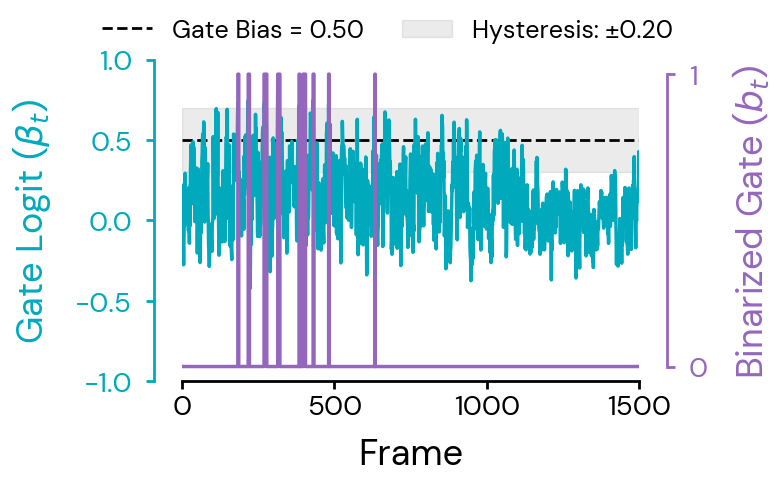

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from pathlib import Path

import matplotlib

matplotlib.rcParams["font.family"] = "DM Sans"

# Static version of the gate-logit / binarized-gate plot — same styling as the
# animation cell above, but rendered once over all timesteps (no cursor, no mp4).
_gate_logits = []
_gate_values = []
for s in af_rollout:
    if hasattr(s, "metrics") and "gate_logit" in s.metrics:
        _gate_logits.append(float(np.asarray(s.metrics["gate_logit"])))
        _gate_values.append(float(np.asarray(s.metrics["gate"])))

if not _gate_logits:
    print(f"No gate_logit found in rollout metrics — mode={af_mode!r} has no gate.")
else:
    _gate_logits = np.array(_gate_logits)
    _gate_values = np.array(_gate_values)
    _T = len(_gate_logits)

    _mode_cfg = af_config.get(af_mode, {})
    _gate_bias = float(_mode_cfg.get("gate_bias", 0.0))
    _gate_margin = float(_mode_cfg.get("gate_margin", 0.0))

    def _round16(x):
        return ((int(x) + 15) // 16) * 16

    _dpi = 100
    _h_px = _round16(AF_RENDER_HEIGHT)
    _w_px = _round16(AF_RENDER_HEIGHT * 1.7)
    _fig, _ax = plt.subplots(figsize=(_w_px / _dpi, _h_px / _dpi), dpi=_dpi)

    _scamper_color = tuple(c / 255 for c in (0, 170, 188))
    _gate_color = (148 / 255, 103 / 255, 189 / 255)

    _x = np.arange(_T)
    _ax.plot(_x, _gate_logits, color=_scamper_color, linewidth=2.5, zorder=3)

    _ax.axhline(
        _gate_bias,
        color="black",
        linestyle="--",
        linewidth=2,
        label=f"Gate Bias = {_gate_bias:.2f}",
        zorder=2,
    )
    if _gate_margin > 0:
        _ax.axhspan(
            _gate_bias - _gate_margin,
            _gate_bias + _gate_margin,
            color="black",
            alpha=0.08,
            zorder=0,
            label=f"Hysteresis: ±{_gate_margin:.2f}",
        )

    _x_max = max(_T - 1, 1)
    _ax.set_xlim(0, _x_max)
    _ax.set_ylim(-1, 1)
    _ax.set_yticks([-1, -0.5, 0, 0.5, 1])

    _ax.set_xlabel("Frame", fontsize=26, labelpad=12)
    _ax.set_ylabel(r"Gate Logit ($\beta_t$)", fontsize=26, labelpad=16)
    _ax.tick_params(labelsize=20, width=2, length=6)
    _ax.tick_params(axis="y", pad=10)

    sns.despine(ax=_ax)
    _ax.spines["bottom"].set_bounds(0, _x_max)
    _ax.spines["left"].set_bounds(-1, 1)
    _ax.spines["left"].set_position(("outward", 20))
    for _spine in ["left", "bottom"]:
        _ax.spines[_spine].set_linewidth(2)

    _ax.spines["left"].set_color(_scamper_color)
    _ax.yaxis.label.set_color(_scamper_color)
    _ax.tick_params(axis="y", colors=_scamper_color)

    _ax2 = _ax.twinx()
    _ax2.plot(
        _x,
        _gate_values,
        color=_gate_color,
        linewidth=2.5,
        drawstyle="steps-post",
        zorder=3,
    )
    _ax2.set_xlim(0, _x_max)
    _ax2.set_ylim(-0.05, 1.05)
    _ax2.set_yticks([0, 1])
    _ax2.set_ylabel(
        r"Binarized Gate ($b_t$)", fontsize=26, labelpad=16, color=_gate_color
    )
    _ax2.tick_params(
        axis="y", labelsize=20, width=2, length=6, pad=10, colors=_gate_color
    )
    _ax2.spines["top"].set_visible(False)
    _ax2.spines["left"].set_visible(False)
    _ax2.spines["right"].set_visible(True)
    _ax2.spines["right"].set_color(_gate_color)
    _ax2.spines["right"].set_linewidth(2)
    _ax2.spines["right"].set_bounds(0, 1)
    _ax2.spines["right"].set_position(("outward", 20))
    _ax2.spines["bottom"].set_visible(False)

    _fig.subplots_adjust(top=0.85, left=0.24, right=0.80, bottom=0.18)
    _ax.legend(
        fontsize=18,
        frameon=False,
        loc="lower center",
        bbox_to_anchor=(0.45, 1.02),
        borderaxespad=0.0,
        ncol=2,
        columnspacing=1.5,
        handlelength=2.0,
    )

    out_dir = Path(AF_OUTPUT_DIR)
    out_dir.mkdir(parents=True, exist_ok=True)
    _run_id = Path(AF_CHECKPOINT_PATH).name
    _gate_stem = (
        f"arena_forage_gate_logit_static_step{AF_CHECKPOINT_STEP}"
        f"_{af_mode}_{_run_id}_seed{AF_SEED}"
    )
    for _ext in ("png", "pdf", "svg"):
        _path = out_dir / f"{_gate_stem}.{_ext}"
        _fig.savefig(_path, dpi=_dpi)
        print(f"Saved {_path}")
    gate_static_path = out_dir / f"{_gate_stem}.png"
    plt.show()
    plt.close(_fig)

Saved /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/arena_forage_sidebyside/arena_forage_heatmap_static_step2_distill_prior_scamper_forage_seed42_t0-1500.png
Saved /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/arena_forage_sidebyside/arena_forage_heatmap_static_step2_distill_prior_scamper_forage_seed42_t0-1500.pdf
Saved /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/arena_forage_sidebyside/arena_forage_heatmap_static_step2_distill_prior_scamper_forage_seed42_t0-1500.svg


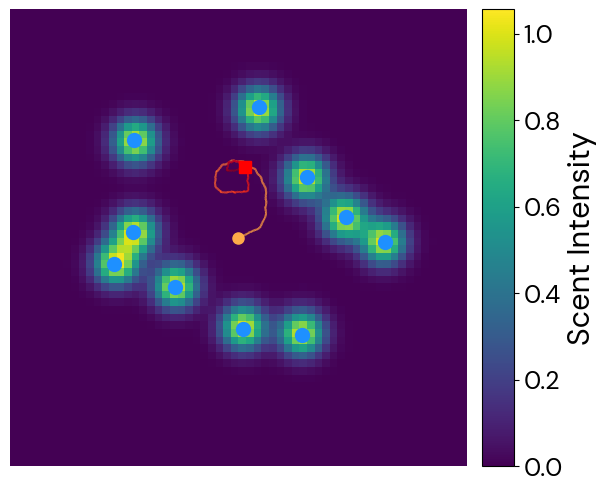

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap
from mpl_toolkits.axes_grid1 import make_axes_locatable
from pathlib import Path

import matplotlib

matplotlib.rcParams["font.family"] = "DM Sans"

# Set to an int frame index (inclusive) to truncate the trajectory; None plots
# the full rollout. Independent of the animation cell — treats stay visible
# regardless of when they were collected.
AF_TRAJ_MAX_FRAME = 1500

# Unwrap to base arena_forage env for config access.
af_base_env = af_env
while hasattr(af_base_env, "env"):
    af_base_env = af_base_env.env
af_env_cfg = af_base_env._config
af_mode = af_config["mode"]

_num_treats = af_env_cfg.num_treats
_sigma = af_env_cfg.scent_sigma
_extent = af_env_cfg.spawn_radius * 1.5
_grid_res = 60
_grid_1d = np.linspace(-_extent, _extent, _grid_res)
_gx, _gy = np.meshgrid(_grid_1d, _grid_1d)

_treat_pos = np.array(af_rollout[0].info["treat_positions"])
_scent_per_treat = np.zeros((_num_treats, _grid_res, _grid_res))
for _i in range(_num_treats):
    _dist2 = (_gx - _treat_pos[_i, 0]) ** 2 + (_gy - _treat_pos[_i, 1]) ** 2
    _scent_per_treat[_i] = np.exp(-_dist2 / (2 * _sigma**2))
_scent_total = _scent_per_treat.sum(axis=0)
_vmax = max(float(_scent_total.max()), 1.0)

_rodent_xy = np.array([np.array(s.data.qpos[:2]) for s in af_rollout])
_num_frames = len(_rodent_xy)
_max_frame = _num_frames - 1 if AF_TRAJ_MAX_FRAME is None else int(AF_TRAJ_MAX_FRAME)
_max_frame = max(0, min(_max_frame, _num_frames - 1))
_traj_xy = _rodent_xy[: _max_frame + 1]

_traj_colors = plt.cm.YlOrRd(np.linspace(0.4, 1.0, 256))
_traj_cmap = LinearSegmentedColormap.from_list("YlOrRd_trunc", _traj_colors)
_start_color = _traj_cmap(0.0)

_dpi = 100
_fig, _ax = plt.subplots(
    figsize=(AF_RENDER_WIDTH / _dpi, AF_RENDER_HEIGHT / _dpi), dpi=_dpi
)

# Full scent floor — all treats visible, even ones collected in the rollout.
_im = _ax.imshow(
    _scent_total,
    extent=[-_extent, _extent, -_extent, _extent],
    origin="lower",
    cmap="viridis",
    vmin=0,
    vmax=_vmax,
    aspect="equal",
)

_ax.plot(
    _treat_pos[:, 0],
    _treat_pos[:, 1],
    "o",
    color="dodgerblue",
    markersize=9,
    markeredgewidth=2,
    linestyle="None",
)

if len(_traj_xy) >= 2:
    _pts = _traj_xy.reshape(-1, 1, 2)
    _segs = np.concatenate([_pts[:-1], _pts[1:]], axis=1)
    _lc = LineCollection(
        _segs,
        cmap=_traj_cmap,
        norm=plt.Normalize(0, _num_frames),
        linewidths=1.5,
        alpha=0.95,
    )
    _lc.set_array(np.arange(len(_pts)))
    _ax.add_collection(_lc)

_ax.plot([_rodent_xy[0, 0]], [_rodent_xy[0, 1]], "o", color=_start_color, markersize=8)
_ax.plot([_traj_xy[-1, 0]], [_traj_xy[-1, 1]], "s", color="red", markersize=8)

_ax.set_xlim(-_extent, _extent)
_ax.set_ylim(-_extent, _extent)
_ax.axis("off")

_divider = make_axes_locatable(_ax)
_cax = _divider.append_axes("right", size="7%", pad=0.15)
_cbar = _fig.colorbar(_im, cax=_cax)
_cbar.set_label("Scent Intensity", fontsize=22)
_cbar.ax.tick_params(labelsize=18)

_fig.tight_layout(pad=0.3)

out_dir = Path(AF_OUTPUT_DIR)
out_dir.mkdir(parents=True, exist_ok=True)
_run_id = Path(AF_CHECKPOINT_PATH).name
_heatmap_stem = (
    f"arena_forage_heatmap_static_step{AF_CHECKPOINT_STEP}"
    f"_{af_mode}_{_run_id}_seed{AF_SEED}_t0-{_max_frame}"
)
for _ext in ("png", "pdf", "svg"):
    _path = out_dir / f"{_heatmap_stem}.{_ext}"
    _fig.savefig(_path, dpi=_dpi)
    print(f"Saved {_path}")
heatmap_static_path = out_dir / f"{_heatmap_stem}.png"
plt.show()
plt.close(_fig)

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/arena_forage_sidebyside/arena_forage_angled_overview_step4_distill_prior_scamper_forage_seed42_t0.[pdf|svg|png]


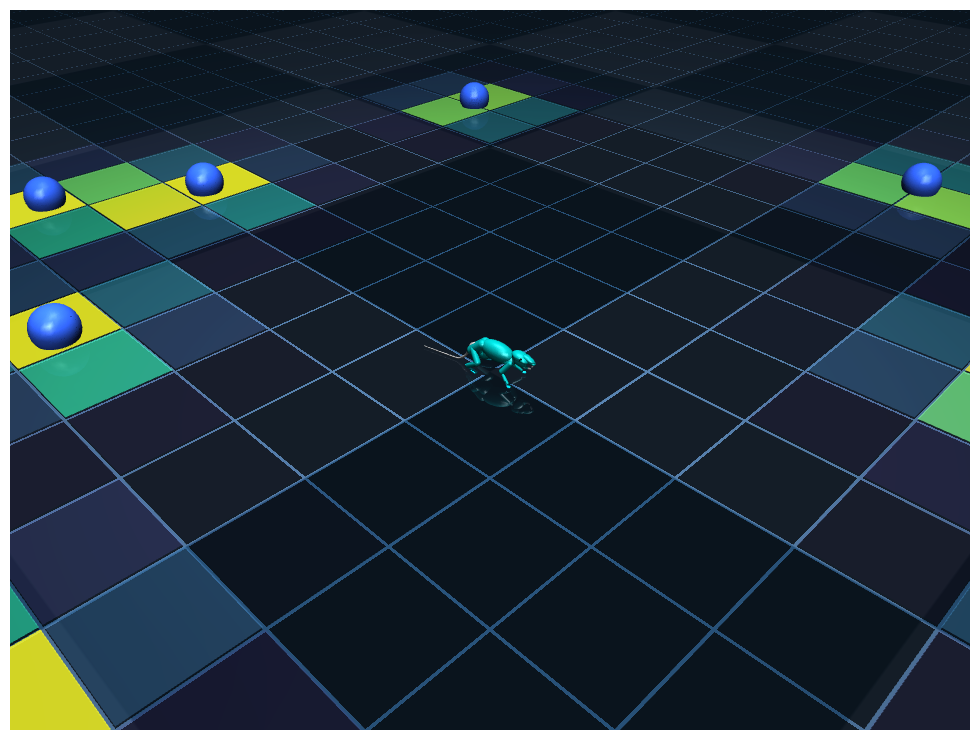

In [8]:
import matplotlib.pyplot as plt
import mujoco
import numpy as np
from matplotlib import cm as mpl_cm
from pathlib import Path

import matplotlib

matplotlib.rcParams["font.family"] = "DM Sans"

# Still rendering of the arena (free camera, angled overview), mirroring the
# snippet in notebooks/analysis/FinalNotebooks/arena_forage_visualization.ipynb.
# Scent floor is drawn as in `ArenaForage.render(..., render_scent=True)`. All
# treats stay visible regardless of rollout collection state.

# Edit these per render.
AF_STILL_FRAME = 0
AF_STILL_HEIGHT = 720
AF_STILL_WIDTH = 960
AF_STILL_AZIMUTH = 135
AF_STILL_ELEVATION = -35
AF_STILL_DISTANCE = 2.0
AF_STILL_LOOKAT = (0.0, 0.0, 0.0)

# Scent rendering knobs (defaults match ArenaForage.render).
AF_STILL_RENDER_SCENT = True
AF_STILL_SCENT_GRID_EXTENT = 5.0
AF_STILL_SCENT_GRID_RESOLUTION = 40
AF_STILL_SCENT_THRESHOLD = 0.0

af_base_env = af_env
while hasattr(af_base_env, "env"):
    af_base_env = af_base_env.env
af_mode = af_config["mode"]

_state = af_rollout[int(AF_STILL_FRAME)]
_treat_positions = np.array(af_rollout[0].info["treat_positions"])
_num_treats = af_base_env._config.num_treats

model = af_base_env.mj_model
model.vis.global_.offwidth = AF_STILL_WIDTH
model.vis.global_.offheight = AF_STILL_HEIGHT

# Place every treat at its initial position so none disappear in the still.
_treat_geom_ids = [
    mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_GEOM, f"treat_{i}")
    for i in range(_num_treats)
]
for j in range(_num_treats):
    model.geom_pos[_treat_geom_ids[j]] = _treat_positions[j]

data = mujoco.MjData(model)
data.qpos = np.array(_state.data.qpos)
data.qvel = np.array(_state.data.qvel)
mujoco.mj_forward(model, data)

renderer = mujoco.Renderer(model, height=AF_STILL_HEIGHT, width=AF_STILL_WIDTH)

cam = mujoco.MjvCamera()
cam.type = mujoco.mjtCamera.mjCAMERA_FREE
cam.fixedcamid = -1
cam.trackbodyid = -1
cam.lookat[:] = AF_STILL_LOOKAT
cam.distance = AF_STILL_DISTANCE
cam.azimuth = AF_STILL_AZIMUTH
cam.elevation = AF_STILL_ELEVATION

renderer.update_scene(data, camera=cam)

# Inject scent floor tiles as visual-only scene geoms (mirrors the per-frame
# logic in ArenaForage.render). All treats contribute — none are masked out.
if AF_STILL_RENDER_SCENT:
    _sigma = af_base_env._config.scent_sigma
    _grid_1d = np.linspace(
        -AF_STILL_SCENT_GRID_EXTENT,
        AF_STILL_SCENT_GRID_EXTENT,
        AF_STILL_SCENT_GRID_RESOLUTION,
    )
    _gx, _gy = np.meshgrid(_grid_1d, _grid_1d)
    _scent_grid = np.zeros_like(_gx)
    for j in range(_num_treats):
        _dist2 = (_gx - _treat_positions[j, 0]) ** 2 + (
            _gy - _treat_positions[j, 1]
        ) ** 2
        _scent_grid += np.exp(-_dist2 / (2 * _sigma**2))

    _tile_half = AF_STILL_SCENT_GRID_EXTENT / AF_STILL_SCENT_GRID_RESOLUTION
    _tile_size = np.array([_tile_half, _tile_half, 0.0001], dtype=np.float64)
    _tile_mat = np.eye(3, dtype=np.float64).flatten()

    _scene = renderer.scene
    for _row in range(AF_STILL_SCENT_GRID_RESOLUTION):
        for _col in range(AF_STILL_SCENT_GRID_RESOLUTION):
            _intensity = _scent_grid[_row, _col]
            if _intensity < AF_STILL_SCENT_THRESHOLD:
                continue
            if _scene.ngeom >= _scene.maxgeom:
                break
            _clamped = min(float(_intensity), 1.0)
            _rgba = np.array(mpl_cm.viridis(_clamped), dtype=np.float32)
            _rgba[3] = _clamped * 0.6
            _pos = np.array([_grid_1d[_col], _grid_1d[_row], 0.0], dtype=np.float64)
            mujoco.mjv_initGeom(
                _scene.geoms[_scene.ngeom],
                mujoco.mjtGeom.mjGEOM_BOX,
                _tile_size,
                _pos,
                _tile_mat,
                _rgba,
            )
            _scene.ngeom += 1

frame = renderer.render()

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.imshow(frame)
ax.axis("off")
plt.tight_layout()

out_dir = Path(AF_OUTPUT_DIR)
out_dir.mkdir(parents=True, exist_ok=True)
_run_id = Path(AF_CHECKPOINT_PATH).name
_still_stem = (
    f"arena_forage_angled_overview_step{AF_CHECKPOINT_STEP}"
    f"_{af_mode}_{_run_id}_seed{AF_SEED}_t{int(AF_STILL_FRAME)}"
)
fig.savefig(out_dir / f"{_still_stem}.pdf", bbox_inches="tight")
fig.savefig(out_dir / f"{_still_stem}.svg", bbox_inches="tight")
fig.savefig(out_dir / f"{_still_stem}.png", bbox_inches="tight", dpi=300)
print(f"Saved to {out_dir / _still_stem}.[pdf|svg|png]")

plt.show()
renderer.close()

In [5]:
import imageio
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap
from mpl_toolkits.axes_grid1 import make_axes_locatable
from pathlib import Path
from IPython.display import Video, display

import matplotlib

matplotlib.rcParams["font.family"] = "DM Sans"

# Self-contained: re-derives sim frames, heatmap panel, and gate panel from
# af_rollout. Three panels concatenated horizontally per frame:
#   [ sim render | scent heatmap + trajectory | gate dynamics ]


def _round16(x):
    return ((int(x) + 15) // 16) * 16


# ===== unwrap env / config =====
af_base_env = af_env
while hasattr(af_base_env, "env"):
    af_base_env = af_base_env.env
af_env_cfg = af_base_env._config
af_mode = af_config["mode"]

# ===== heatmap data =====
_num_treats = af_env_cfg.num_treats
_sigma = af_env_cfg.scent_sigma
_extent = af_env_cfg.spawn_radius * 1.5
_grid_res = 60
_grid_1d = np.linspace(-_extent, _extent, _grid_res)
_gx, _gy = np.meshgrid(_grid_1d, _grid_1d)

_treat_pos = np.array(af_rollout[0].info["treat_positions"])
_scent_per_treat = np.zeros((_num_treats, _grid_res, _grid_res))
for _i in range(_num_treats):
    _dist2 = (_gx - _treat_pos[_i, 0]) ** 2 + (_gy - _treat_pos[_i, 1]) ** 2
    _scent_per_treat[_i] = np.exp(-_dist2 / (2 * _sigma**2))
_vmax = max(float(_scent_per_treat.sum(axis=0).max()), 1.0)

_treat_collected_per_frame = np.array(
    [np.array(s.info["treat_collected"]) for s in af_rollout]
)
_rodent_xy = np.array([np.array(s.data.qpos[:2]) for s in af_rollout])

_traj_colors = plt.cm.YlOrRd(np.linspace(0.4, 1.0, 256))
_traj_cmap = LinearSegmentedColormap.from_list("YlOrRd_trunc", _traj_colors)
_start_color = _traj_cmap(0.0)

# ===== sim frames =====
print("Rendering sim frames...")
sim_frames = af_base_env.render(
    af_rollout,
    camera=AF_SIM_CAMERA_NAME,
    height=AF_RENDER_HEIGHT,
    width=AF_RENDER_WIDTH,
    render_scent=True,
)
sim_frames = [np.asarray(f) for f in sim_frames]
_num_frames = len(sim_frames)
print(f"  {_num_frames} sim frames at {sim_frames[0].shape}")

# ===== heatmap figure =====
_dpi = 100
_hm_fig, _hm_ax = plt.subplots(
    figsize=(AF_RENDER_WIDTH / _dpi, AF_RENDER_HEIGHT / _dpi),
    dpi=_dpi,
)
_hm_canvas = FigureCanvasAgg(_hm_fig)
_hm_im = _hm_ax.imshow(
    _scent_per_treat.sum(axis=0),
    extent=[-_extent, _extent, -_extent, _extent],
    origin="lower",
    cmap="viridis",
    vmin=0,
    vmax=_vmax,
    aspect="equal",
)
(_hm_active,) = _hm_ax.plot(
    _treat_pos[:, 0],
    _treat_pos[:, 1],
    "o",
    color="dodgerblue",
    markersize=9,
    markeredgewidth=2,
    linestyle="None",
)
(_hm_collected,) = _hm_ax.plot(
    [],
    [],
    "x",
    color="gray",
    markersize=9,
    markeredgewidth=2,
    linestyle="None",
)
_hm_lc = LineCollection(
    [],
    cmap=_traj_cmap,
    norm=plt.Normalize(0, _num_frames),
    linewidths=1.5,
    alpha=0.9,
)
_hm_ax.add_collection(_hm_lc)
(_hm_start,) = _hm_ax.plot(
    [_rodent_xy[0, 0]],
    [_rodent_xy[0, 1]],
    "o",
    color=_start_color,
    markersize=8,
)
(_hm_end,) = _hm_ax.plot([], [], "s", color="red", markersize=8)
_hm_ax.set_xlim(-_extent, _extent)
_hm_ax.set_ylim(-_extent, _extent)
_hm_ax.axis("off")

_divider = make_axes_locatable(_hm_ax)
_cax = _divider.append_axes("right", size="7%", pad=0.15)
_cbar = _hm_fig.colorbar(_hm_im, cax=_cax)
_cbar.set_label("Scent Intensity", fontsize=22)
_cbar.ax.tick_params(labelsize=18)
_hm_fig.tight_layout(pad=0.3)

# ===== gate panel (only for modes that emit gate metrics) =====
_gate_logits_arr, _gate_values_arr = [], []
for s in af_rollout:
    if hasattr(s, "metrics") and "gate_logit" in s.metrics:
        _gate_logits_arr.append(float(np.asarray(s.metrics["gate_logit"])))
        _gate_values_arr.append(float(np.asarray(s.metrics["gate"])))
_have_gate = bool(_gate_logits_arr)

if _have_gate:
    _gate_logits_arr = np.array(_gate_logits_arr)
    _gate_values_arr = np.array(_gate_values_arr)
    _T_gate = len(_gate_logits_arr)

    _mode_cfg = af_config.get(af_mode, {})
    _gate_bias = float(_mode_cfg.get("gate_bias", 0.0))
    _gate_margin = float(_mode_cfg.get("gate_margin", 0.0))

    _gate_h_px = _round16(AF_RENDER_HEIGHT)
    _gate_w_px = _round16(AF_RENDER_HEIGHT * 1.7)
    _gate_fig, _gate_ax = plt.subplots(
        figsize=(_gate_w_px / _dpi, _gate_h_px / _dpi),
        dpi=_dpi,
    )
    _gate_canvas = FigureCanvasAgg(_gate_fig)

    _scamper_color = tuple(c / 255 for c in (0, 170, 188))
    _gate_color = (148 / 255, 103 / 255, 189 / 255)

    (_gate_logit_line,) = _gate_ax.plot(
        [],
        [],
        color=_scamper_color,
        linewidth=2.5,
        zorder=3,
    )
    _gate_cursor = _gate_ax.axvline(
        0,
        color=tuple(c / 255 for c in (189, 19, 0)),
        linewidth=2,
        alpha=0.9,
        zorder=4,
    )

    _gate_ax.axhline(
        _gate_bias,
        color="black",
        linestyle="--",
        linewidth=2,
        label=f"Gate Bias = {_gate_bias:.2f}",
        zorder=2,
    )
    if _gate_margin > 0:
        _gate_ax.axhspan(
            _gate_bias - _gate_margin,
            _gate_bias + _gate_margin,
            color="black",
            alpha=0.08,
            zorder=0,
            label=f"Hysteresis: ±{_gate_margin:.2f}",
        )

    _gx_max = max(_T_gate - 1, 1)
    _gate_ax.set_xlim(0, _gx_max)
    _gate_ax.set_ylim(-1, 1)
    _gate_ax.set_yticks([-1, -0.5, 0, 0.5, 1])
    _gate_ax.set_xlabel("Frame", fontsize=26, labelpad=12)
    _gate_ax.set_ylabel(r"Gate Logit ($\beta_t$)", fontsize=26, labelpad=16)
    _gate_ax.tick_params(labelsize=20, width=2, length=6)
    _gate_ax.tick_params(axis="y", pad=10)

    sns.despine(ax=_gate_ax)
    _gate_ax.spines["bottom"].set_bounds(0, _gx_max)
    _gate_ax.spines["left"].set_bounds(-1, 1)
    _gate_ax.spines["left"].set_position(("outward", 20))
    for _spine in ["left", "bottom"]:
        _gate_ax.spines[_spine].set_linewidth(2)
    _gate_ax.spines["left"].set_color(_scamper_color)
    _gate_ax.yaxis.label.set_color(_scamper_color)
    _gate_ax.tick_params(axis="y", colors=_scamper_color)

    _gate_ax2 = _gate_ax.twinx()
    (_gate_step_line,) = _gate_ax2.plot(
        [],
        [],
        color=_gate_color,
        linewidth=2.5,
        drawstyle="steps-post",
        zorder=3,
    )
    _gate_ax2.set_xlim(0, _gx_max)
    _gate_ax2.set_ylim(-0.05, 1.05)
    _gate_ax2.set_yticks([0, 1])
    _gate_ax2.set_ylabel(
        r"Binarized Gate ($b_t$)",
        fontsize=26,
        labelpad=16,
        color=_gate_color,
    )
    _gate_ax2.tick_params(
        axis="y",
        labelsize=20,
        width=2,
        length=6,
        pad=10,
        colors=_gate_color,
    )
    _gate_ax2.spines["top"].set_visible(False)
    _gate_ax2.spines["left"].set_visible(False)
    _gate_ax2.spines["right"].set_visible(True)
    _gate_ax2.spines["right"].set_color(_gate_color)
    _gate_ax2.spines["right"].set_linewidth(2)
    _gate_ax2.spines["right"].set_bounds(0, 1)
    _gate_ax2.spines["right"].set_position(("outward", 20))
    _gate_ax2.spines["bottom"].set_visible(False)

    _gate_fig.subplots_adjust(top=0.85, left=0.24, right=0.80, bottom=0.18)
    _gate_ax.legend(
        fontsize=18,
        frameon=False,
        loc="lower center",
        bbox_to_anchor=(0.45, 1.02),
        borderaxespad=0.0,
        ncol=2,
        columnspacing=1.5,
        handlelength=2.0,
    )
else:
    print(f"  no gate metrics for mode={af_mode!r} - panel will be omitted.")

# ===== composite frames =====
print("Compositing 3-panel frames...")
combined_frames = []
for t in range(_num_frames):
    # heatmap update
    collected = _treat_collected_per_frame[t]
    active = ~collected
    if active.any():
        _hm_im.set_data(_scent_per_treat[active].sum(axis=0))
    else:
        _hm_im.set_data(np.zeros_like(_gx))
    _hm_active.set_data(_treat_pos[active, 0], _treat_pos[active, 1])
    _hm_collected.set_data(_treat_pos[collected, 0], _treat_pos[collected, 1])
    pts = _rodent_xy[: t + 1].reshape(-1, 1, 2)
    if len(pts) >= 2:
        segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
        _hm_lc.set_segments(segs)
        _hm_lc.set_array(np.arange(len(pts)))
    _hm_end.set_data([_rodent_xy[t, 0]], [_rodent_xy[t, 1]])
    _hm_canvas.draw()
    hm_frame = np.asarray(_hm_canvas.buffer_rgba())[:, :, :3]

    panels = [sim_frames[t], hm_frame]

    if _have_gate:
        gt = min(t, _T_gate - 1)
        _gate_logit_line.set_data(np.arange(gt + 1), _gate_logits_arr[: gt + 1])
        _gate_step_line.set_data(np.arange(gt + 1), _gate_values_arr[: gt + 1])
        _gate_cursor.set_xdata([gt, gt])
        _gate_canvas.draw()
        panels.append(np.asarray(_gate_canvas.buffer_rgba())[:, :, :3])

    h = min(p.shape[0] for p in panels)
    panels = [p[:h] for p in panels]
    combined_frames.append(np.concatenate(panels, axis=1))

plt.close(_hm_fig)
if _have_gate:
    plt.close(_gate_fig)

# Pad final width to a multiple of 16 (H.264 macroblock alignment).
_final_w = combined_frames[0].shape[1]
_pad = (-_final_w) % 16
if _pad:
    combined_frames = [
        np.pad(f, ((0, 0), (0, _pad), (0, 0)), constant_values=255)
        for f in combined_frames
    ]
print(f"  built {len(combined_frames)} frames at {combined_frames[0].shape}")

# ===== write mp4 =====
out_dir = Path(AF_OUTPUT_DIR)
out_dir.mkdir(parents=True, exist_ok=True)
_run_id = Path(AF_CHECKPOINT_PATH).name
out_path = out_dir / f"arena_forage_3panel_{af_mode}_{_run_id}_seed{AF_SEED}.mp4"
with imageio.get_writer(str(out_path), fps=AF_RENDER_FPS) as writer:
    for f in combined_frames:
        writer.append_data(f)
print(f"Saved {out_path}")
display(Video(str(out_path), embed=True))

Rendering sim frames...
  1501 sim frames at (480, 640, 3)
  no gate metrics for mode='distill_prior_no_rgm' - panel will be omitted.
Compositing 3-panel frames...
  built 1501 frames at (480, 1280, 3)


/home/mila/a/aidan.sirbu/.local/share/uv/python/cpython-3.12.12-linux-x86_64-gnu/lib/python3.12/subprocess.py:1885: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = _fork_exec(


Saved /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/arena_forage_sidebyside/arena_forage_3panel_distill_prior_no_rgm_norgm_forage_seed42.mp4


# Walk-Rear Task Transfer

Self-contained section: roll out a checkpoint trained on the `walk_rear` task
and render an mp4. Supports `decoder_only`, `prior_decoder`, `distill`, and
`scratch` training modes — the loader picks the right wrapper / network from
the checkpoint's saved `mode`.


In [14]:
# ============ EDIT THESE ============
WR_CHECKPOINT_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/walk_rear_checkpoints/260415_194114_644658"
WR_CHECKPOINT_STEP = 34  # None = latest
WR_SEED = 0
WR_EPISODE_LENGTH = 250

# ============ RENDER SETTINGS ============
WR_RENDER_HEIGHT = 720
WR_RENDER_WIDTH = 1280
WR_RENDER_FPS = 50
WR_RENDER_CAMERA = "close_profile-rodent"  # used when WR_USE_FREE_CAMERA=False

WR_OUTPUT_DIR = (
    "/home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots"
)

# ============ FREE-CAMERA SETTINGS ============
# Set WR_USE_FREE_CAMERA=True to render with a fixed-in-world mjvCamera built
# from these params instead of the named WR_RENDER_CAMERA above. Tune the
# values via the interactive cell at the bottom of this section, then paste
# them here for reproducible re-runs from a fresh kernel.
WR_USE_FREE_CAMERA = True
WR_FREE_CAMERA_DISTANCE = 1.0
WR_FREE_CAMERA_AZIMUTH = 90.0
WR_FREE_CAMERA_ELEVATION = -15.0
WR_FREE_CAMERA_LOOKAT = (0.46, 0.0, 0.05)

# ============ OPTIONAL ENV OVERRIDES (None = use checkpoint's saved value) ====
WR_TARGET_X = None
WR_TARGET_Y = None
WR_TARGET_Z = None

In [15]:
import os

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
os.environ.setdefault("MUJOCO_GL", "egl")
os.environ.setdefault("PYOPENGL_PLATFORM", "egl")

import functools

import jax
import jax.numpy as jnp
import orbax.checkpoint as ocp
from brax.training.acme import running_statistics, specs
from brax.training.agents.ppo import networks as ppo_networks
from mujoco import mjx
from omegaconf import OmegaConf

from scamper.agent.task_transfer.walk_rear.checkpoint_utils import (
    _STEP_PREFIX as _WR_STEP_PREFIX,
    _create_abstract_prior_policy as _wr_create_abstract_prior_policy,
    load_task_transfer_brax_params as _wr_load_task_transfer_brax_params,
    load_task_transfer_metadata as _wr_load_task_transfer_metadata,
    make_decoder_inference_fn as _wr_make_decoder_inference_fn,
    make_prior_inference_fn as _wr_make_prior_inference_fn,
)
from scamper.agent.task_transfer.walk_rear.scratch_networks import (
    make_scratch_ppo_networks as _wr_make_scratch_ppo_networks,
)
from scamper.agent.task_transfer.walk_rear.wrappers import (
    DecoderHighLevelWrapper as _WRDecoderHighLevelWrapper,
    FlatObsWrapper as _WRFlatObsWrapper,
    PriorDecoderHighLevelWrapper as _WRPriorDecoderHighLevelWrapper,
)
from scamper.environment.rodent import consts as _wr_rodent_consts
from scamper.environment.rodent import walk_rear as _wr_walk_rear


def _wr_load_frozen_networks(checkpoint_path, step, mode, ckpt_cfg):
    """Restore the imitation-stage frozen networks from a walk_rear checkpoint.

    walk_rear's abstract uses imitation IntentionEncoder (fc2_mean / fc2_logvar)
    so the on-disk encoder structure matches and StandardRestore works. Scratch
    still saves frozen_networks (loaded from a prior checkpoint at train time)
    so we restore for all four modes uniformly.
    """
    abstract_normalizer, abstract_combined = _wr_create_abstract_prior_policy(
        OmegaConf.create(ckpt_cfg)
    )
    abstract_frozen = {
        "encoder_params": abstract_combined["params"]["encoder"],
        "prior_params": abstract_combined["params"]["prior"],
        "decoder_params": abstract_combined["params"]["decoder"],
        "imitation_normalizer": abstract_normalizer,
    }
    mgr_options = ocp.CheckpointManagerOptions(
        create=False, step_prefix=_WR_STEP_PREFIX
    )
    with ocp.CheckpointManager(checkpoint_path, options=mgr_options) as mgr:
        data = mgr.restore(
            step,
            args=ocp.args.Composite(
                frozen_networks=ocp.args.StandardRestore(abstract_frozen),
            ),
        )
    return data["frozen_networks"]


def wr_load_model(
    checkpoint_path,
    checkpoint_step=None,
    target_x=None,
    target_y=None,
    target_z=None,
):
    """Load a trained walk_rear task-transfer checkpoint.

    Returns (jit_reset, jit_step, jit_inference_fn, brax_params, env, config).
    """
    info = _wr_load_task_transfer_metadata(checkpoint_path, step=checkpoint_step)
    config = info["config"]
    step = info["step"]
    mode = config["mode"]
    ckpt_cfg = config["checkpoint_config"]

    print(f"Loading walk_rear checkpoint: {checkpoint_path}")
    print(f"  Mode: {mode}, Step: {step}")

    frozen = _wr_load_frozen_networks(checkpoint_path, step, mode, ckpt_cfg)
    prior_params = frozen["prior_params"]
    decoder_params = frozen["decoder_params"]
    normalizer_params = frozen["imitation_normalizer"]

    latent_size = ckpt_cfg["network_config"]["intention_size"]
    proprio_size = ckpt_cfg["network_config"]["obs_sizes"]["proprioception"]

    env_cfg = _wr_walk_rear.default_config()
    xml_variant = config["env"].get("xml_variant", "full-collisions")
    xml_map = {
        "limited-collisions": _wr_rodent_consts.RODENT_XML_PATH,
        "full-collisions": _wr_rodent_consts.RODENT_FULL_COLLISION_XML,
        "no-tail-collisions": _wr_rodent_consts.RODENT_NO_TAIL_COLLISION_XML,
    }
    env_cfg.walker_xml_path = xml_map[xml_variant]
    env_cfg.mujoco_impl = config["env"].get("mujoco_impl", "jax")
    env_cfg.ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
    env_cfg.target_x = config["env"]["target_x"] if target_x is None else target_x
    env_cfg.target_y = config["env"]["target_y"] if target_y is None else target_y
    env_cfg.target_z = config["env"]["target_z"] if target_z is None else target_z
    env_cfg.xy_tolerance = config["env"]["xy_tolerance"]
    env_cfg.z_tolerance = config["env"]["z_tolerance"]
    env_cfg.hold_duration = config["env"]["hold_duration"]
    env_cfg.distance_margin = config["env"]["distance_margin"]
    if config["env"].get("reward_weights"):
        env_cfg.reward_terms = {
            "distance_to_target": {
                "weight": config["env"]["reward_weights"]["distance_to_target"]
            },
            "walk_rear_success": {
                "weight": config["env"]["reward_weights"]["walk_rear_success"]
            },
            "control_diff_cost": {
                "weight": config["env"]["reward_weights"]["control_diff_cost"]
            },
        }
    if mode == "scratch":
        env_cfg.torque_actuators = config.get("scratch", {}).get(
            "torque_actuators", True
        )
    else:
        env_cfg.torque_actuators = True

    decoder_fn = _wr_make_decoder_inference_fn(
        decoder_params, normalizer_params, ckpt_cfg
    )
    base_env = _wr_walk_rear.WalkRear(config=env_cfg)
    base_env._mjx_model = mjx.put_model(base_env._mj_model, impl=env_cfg.mujoco_impl)

    if mode == "decoder_only":
        env = _WRDecoderHighLevelWrapper(
            base_env, decoder_fn, latent_size, proprio_size
        )
    elif mode == "scratch":
        env = _WRFlatObsWrapper(base_env)
    elif mode in ("prior_decoder", "distill"):
        prior_fn = _wr_make_prior_inference_fn(
            prior_params, normalizer_params, ckpt_cfg
        )
        mcfg = config[mode]
        env = _WRPriorDecoderHighLevelWrapper(
            base_env,
            prior_fn,
            decoder_fn,
            latent_size,
            proprio_size,
            deterministic_prior=mcfg["deterministic_prior"],
            noise_logvar=mcfg["noise_logvar"],
        )
    else:
        raise ValueError(f"Unknown walk_rear mode: {mode}")

    jit_reset = jax.jit(env.reset)
    jit_step = jax.jit(env.step)

    start_state = jit_reset(jax.random.PRNGKey(0))
    obs_size = start_state.obs.shape[-1]
    policy_action_size = env.action_size
    normalize = running_statistics.normalize

    if mode == "scratch":
        task_obs_size = obs_size - proprio_size
        decoder_hidden_layer_sizes = tuple(
            ckpt_cfg["network_config"]["decoder_layer_sizes"]
        )

        def network_factory(*args, **kwargs):
            return _wr_make_scratch_ppo_networks(
                task_obs_size=task_obs_size,
                proprio_size=proprio_size,
                action_size=policy_action_size,
                latent_size=latent_size,
                policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
                decoder_hidden_layer_sizes=decoder_hidden_layer_sizes,
                value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
            )

        dummy_net = network_factory()
    else:
        network_factory = functools.partial(
            ppo_networks.make_ppo_networks,
            policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
            value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
        )
        dummy_net = network_factory(
            obs_size, policy_action_size, preprocess_observations_fn=normalize
        )

    key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
    dummy_normalizer = running_statistics.init_state(
        specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
    )
    dummy_policy = dummy_net.policy_network.init(key_p)
    dummy_value = dummy_net.value_network.init(key_v)
    abstract_brax_params = (dummy_normalizer, dummy_policy, dummy_value)

    brax_params = _wr_load_task_transfer_brax_params(
        checkpoint_path, abstract_brax_params, step=step
    )

    if mode == "scratch":
        ppo_network = network_factory()
    else:
        ppo_network = network_factory(
            obs_size, policy_action_size, preprocess_observations_fn=normalize
        )
    policy_network = ppo_network.policy_network
    parametric_action_distribution = ppo_network.parametric_action_distribution

    def inference_fn(params, observations, key_sample):
        del key_sample
        param_subset = (params[0], params[1])
        logits = policy_network.apply(*param_subset, observations)
        action = parametric_action_distribution.mode(logits)
        return action, {}

    jit_inference_fn = jax.jit(inference_fn)
    print("  Walk-rear model loaded.")
    return jit_reset, jit_step, jit_inference_fn, brax_params, env, config

In [16]:
import jax
from jax import random
import numpy as np

(
    wr_jit_reset,
    wr_jit_step,
    wr_jit_inference_fn,
    wr_brax_params,
    wr_env,
    wr_config,
) = wr_load_model(
    WR_CHECKPOINT_PATH,
    checkpoint_step=WR_CHECKPOINT_STEP,
    target_x=WR_TARGET_X,
    target_y=WR_TARGET_Y,
    target_z=WR_TARGET_Z,
)

rng = random.PRNGKey(WR_SEED)
reset_rng, act_rng = random.split(rng)
state = wr_jit_reset(reset_rng)
wr_rollout = [state]
for _step in range(WR_EPISODE_LENGTH):
    _, act_rng = random.split(act_rng)
    action, _ = wr_jit_inference_fn(wr_brax_params, state.obs, act_rng)
    state = wr_jit_step(state, action)
    wr_rollout.append(state)
    if bool(state.done):
        print(f"Episode terminated at step {_step + 1}")
        break

wr_mode = wr_config["mode"]
final_hold = int(np.asarray(wr_rollout[-1].info.get("hold_steps", 0)))
print(
    f"Rollout: {len(wr_rollout)} frames, mode={wr_mode}, "
    f"final hold_steps={final_hold}"
)

Loading walk_rear checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/walk_rear_checkpoints/260415_194114_644658
  Mode: scratch, Step: 34
  Walk-rear model loaded.
Rollout: 251 frames, mode=scratch, final hold_steps=0


In [17]:
import imageio
import mujoco
import numpy as np
from pathlib import Path
from IPython.display import Video, display

# Unwrap to the base WalkRear env for rendering.
wr_base_env = wr_env
while hasattr(wr_base_env, "env"):
    wr_base_env = wr_base_env.env


def _wr_resolve_camera():
    """Return either the named camera string or a free-camera mjvCamera."""
    if not WR_USE_FREE_CAMERA:
        return WR_RENDER_CAMERA
    cam = mujoco.MjvCamera()
    cam.type = mujoco.mjtCamera.mjCAMERA_FREE
    cam.fixedcamid = -1
    cam.trackbodyid = -1
    cam.lookat[:] = WR_FREE_CAMERA_LOOKAT
    cam.distance = float(WR_FREE_CAMERA_DISTANCE)
    cam.azimuth = float(WR_FREE_CAMERA_AZIMUTH)
    cam.elevation = float(WR_FREE_CAMERA_ELEVATION)
    return cam


_wr_camera = _wr_resolve_camera()
print(
    f"Rendering walk_rear sim frames "
    f"({'free camera' if WR_USE_FREE_CAMERA else f'camera={WR_RENDER_CAMERA!r}'})..."
)
sim_frames = wr_base_env.render(
    wr_rollout,
    camera=_wr_camera,
    height=WR_RENDER_HEIGHT,
    width=WR_RENDER_WIDTH,
)
sim_frames = [np.asarray(f) for f in sim_frames]
print(f"  {len(sim_frames)} frames at {sim_frames[0].shape}")

# Pad to multiple of 16 along width for codec compatibility.
_pad = (-sim_frames[0].shape[1]) % 16
if _pad:
    sim_frames = [
        np.pad(f, ((0, 0), (0, _pad), (0, 0)), constant_values=255) for f in sim_frames
    ]

out_dir = Path(WR_OUTPUT_DIR)
out_dir.mkdir(parents=True, exist_ok=True)
_run_id = Path(WR_CHECKPOINT_PATH).name
_cam_suffix = "_freecam" if WR_USE_FREE_CAMERA else ""
out_path = out_dir / f"walk_rear_{wr_mode}_{_run_id}_seed{WR_SEED}{_cam_suffix}.mp4"
with imageio.get_writer(str(out_path), fps=WR_RENDER_FPS) as writer:
    for f in sim_frames:
        writer.append_data(f)
print(f"Saved {out_path}")
display(Video(str(out_path), embed=True))

Rendering walk_rear sim frames (free camera)...


100%|██████████| 251/251 [00:02<00:00, 108.41it/s]


  251 frames at (720, 1280, 3)
Saved /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/walk_rear_scratch_260415_194114_644658_seed0_freecam.mp4


## Interactive camera tuning (free camera)

Build an `mjvCamera` from sliders (`distance`, `azimuth`, `elevation`, and 3
`lookat` axes) so we can frame the scene with a fixed-in-world camera instead
of relying on the model's tracking camera. The chosen parameters are stored in
`WR_FREE_CAMERA` and used by the **Render full mp4** button to write
`walk_rear_{mode}_{run_id}_seed{seed}_freecam.mp4`.


In [11]:
import io
from pathlib import Path

import imageio
import ipywidgets as widgets
import mujoco
import numpy as np
import PIL.Image
from IPython.display import Video, display
from IPython.display import display as ipy_display

# Mutable container for the chosen camera params; live-updated by the sliders
# so the next "Render full mp4" click picks them up.
WR_FREE_CAMERA = {
    "distance": float(WR_FREE_CAMERA_DISTANCE),
    "azimuth": float(WR_FREE_CAMERA_AZIMUTH),
    "elevation": float(WR_FREE_CAMERA_ELEVATION),
    "lookat": list(WR_FREE_CAMERA_LOOKAT),
}

# Reuse the unwrapped base WalkRear env for camera/preview rendering.
_wr_base_for_cam = wr_env
while hasattr(_wr_base_for_cam, "env"):
    _wr_base_for_cam = _wr_base_for_cam.env

# Preview is modest-resolution so slider drags stay responsive.
_WR_PREVIEW_H = 720
_WR_PREVIEW_W = 1280
_wr_cam_renderer = mujoco.Renderer(
    _wr_base_for_cam.mj_model, height=_WR_PREVIEW_H, width=_WR_PREVIEW_W
)
_wr_cam_data = mujoco.MjData(_wr_base_for_cam.mj_model)


def _wr_build_free_camera():
    cam = mujoco.MjvCamera()
    cam.type = mujoco.mjtCamera.mjCAMERA_FREE
    cam.fixedcamid = -1
    cam.trackbodyid = -1
    cam.lookat[:] = WR_FREE_CAMERA["lookat"]
    cam.distance = float(WR_FREE_CAMERA["distance"])
    cam.azimuth = float(WR_FREE_CAMERA["azimuth"])
    cam.elevation = float(WR_FREE_CAMERA["elevation"])
    return cam


def _wr_render_preview(frame_idx):
    state = wr_rollout[frame_idx]
    _wr_cam_data.qpos[:] = np.asarray(state.data.qpos)
    _wr_cam_data.qvel[:] = np.asarray(state.data.qvel)
    mujoco.mj_forward(_wr_base_for_cam.mj_model, _wr_cam_data)
    _wr_cam_renderer.update_scene(_wr_cam_data, camera=_wr_build_free_camera())
    return _wr_cam_renderer.render()


# Sliders.
_slider_kw = dict(continuous_update=False, layout=widgets.Layout(width="320px"))
_distance = widgets.FloatSlider(
    value=WR_FREE_CAMERA["distance"],
    min=0.2,
    max=4.0,
    step=0.05,
    description="distance",
    **_slider_kw,
)
_azimuth = widgets.FloatSlider(
    value=WR_FREE_CAMERA["azimuth"],
    min=-180.0,
    max=180.0,
    step=1.0,
    description="azimuth",
    **_slider_kw,
)
_elevation = widgets.FloatSlider(
    value=WR_FREE_CAMERA["elevation"],
    min=-89.0,
    max=89.0,
    step=1.0,
    description="elevation",
    **_slider_kw,
)
_lookat_x = widgets.FloatSlider(
    value=WR_FREE_CAMERA["lookat"][0],
    min=-2.0,
    max=2.0,
    step=0.01,
    description="lookat_x",
    **_slider_kw,
)
_lookat_y = widgets.FloatSlider(
    value=WR_FREE_CAMERA["lookat"][1],
    min=-2.0,
    max=2.0,
    step=0.01,
    description="lookat_y",
    **_slider_kw,
)
_lookat_z = widgets.FloatSlider(
    value=WR_FREE_CAMERA["lookat"][2],
    min=-1.0,
    max=1.0,
    step=0.01,
    description="lookat_z",
    **_slider_kw,
)
_frame_idx = widgets.IntSlider(
    value=min(len(wr_rollout) // 2, len(wr_rollout) - 1),
    min=0,
    max=max(len(wr_rollout) - 1, 0),
    step=1,
    description="frame",
    **_slider_kw,
)

_preview = widgets.Image(format="png")
_status = widgets.HTML()
_render_btn = widgets.Button(
    description="Render full mp4 with this camera",
    button_style="primary",
    layout=widgets.Layout(width="320px"),
)
_render_out = widgets.Output()


def _on_change(*_):
    WR_FREE_CAMERA["distance"] = _distance.value
    WR_FREE_CAMERA["azimuth"] = _azimuth.value
    WR_FREE_CAMERA["elevation"] = _elevation.value
    WR_FREE_CAMERA["lookat"] = [_lookat_x.value, _lookat_y.value, _lookat_z.value]
    img = _wr_render_preview(_frame_idx.value)
    buf = io.BytesIO()
    PIL.Image.fromarray(img).save(buf, format="PNG")
    _preview.value = buf.getvalue()
    _status.value = (
        f"<code>WR_FREE_CAMERA = {WR_FREE_CAMERA}</code>"
        f" &nbsp; (preview frame {_frame_idx.value} / {len(wr_rollout) - 1})"
    )


for _w in (
    _distance,
    _azimuth,
    _elevation,
    _lookat_x,
    _lookat_y,
    _lookat_z,
    _frame_idx,
):
    _w.observe(_on_change, names="value")
_on_change()


def _on_render_click(_):
    with _render_out:
        _render_out.clear_output()
        cam = _wr_build_free_camera()
        print("Rendering full mp4 with current free camera...")
        frames = _wr_base_for_cam.render(
            wr_rollout,
            camera=cam,
            height=WR_RENDER_HEIGHT,
            width=WR_RENDER_WIDTH,
        )
        frames = [np.asarray(f) for f in frames]
        _pad = (-frames[0].shape[1]) % 16
        if _pad:
            frames = [
                np.pad(f, ((0, 0), (0, _pad), (0, 0)), constant_values=255)
                for f in frames
            ]
        out_dir = Path(WR_OUTPUT_DIR)
        out_dir.mkdir(parents=True, exist_ok=True)
        _run_id = Path(WR_CHECKPOINT_PATH).name
        out_path = out_dir / f"walk_rear_{wr_mode}_{_run_id}_seed{WR_SEED}_freecam.mp4"
        with imageio.get_writer(str(out_path), fps=WR_RENDER_FPS) as writer:
            for f in frames:
                writer.append_data(f)
        print(f"Saved {out_path}")
        display(Video(str(out_path), embed=True))


_render_btn.on_click(_on_render_click)

ipy_display(
    widgets.VBox(
        [
            widgets.HBox([_distance, _frame_idx]),
            widgets.HBox([_azimuth, _elevation]),
            widgets.HBox([_lookat_x, _lookat_y, _lookat_z]),
            _preview,
            _status,
            _render_btn,
            _render_out,
        ]
    )
)

# Teacher Rollout from Distill Checkpoint — 3×3 Grid

Self-contained section: take a **distill** checkpoint, load the frozen MLP
teacher it was distilled from, and roll the teacher out on `IM_NUM_CLIPS`
reference clips. The render assembles all rollouts into a single 3×3 grid of
rodents (each cell colored from the `tab10` palette, cycled — same convention
as the 3×3 grid renderings above) with each rodent's reference-target ghost
overlaid in the matching colour at lower alpha. The interactive cell at the
end lets you tune the camera (azimuth / elevation / distance / lookat).


In [1]:
# ============ EDIT THESE ============
IM_DISTILL_CHECKPOINT_PATH = (
    "/home/mila/a/aidan.sirbu/SCAMPER/scratch/distill_checkpoints/260327_134740_079934"
)
IM_DISTILL_CHECKPOINT_STEP = None  # None = latest

# Optional override of the teacher checkpoint path baked into the distill cfg.
IM_TEACHER_CHECKPOINT_PATH = None
IM_TEACHER_CHECKPOINT_STEP = None  # None = latest

# Optional override of the reference data path (HDF5).
IM_REFERENCE_DATA_PATH = (
    "/home/mila/a/aidan.sirbu/SCAMPER/data/rodent/rodent_reference_clips.h5"
)

# Rollout / clip selection
# 9 clip indices to roll out and render in the 3x3 grid below. Length
# must equal IM_GRID_ROWS * IM_GRID_COLS.
IM_CLIP_INDICES = [2, 8, 11, 15, 22, 23, 25, 27, 30]
IM_NUM_CLIPS = len(IM_CLIP_INDICES)
IM_SEED = 42
IM_EPISODE_LENGTH = None  # None = (clip_length - reference_length) * steps_per_frame

# Backend / walker overrides applied to the distill cfg before building the env.
IM_MUJOCO_IMPL = "warp"  # "jax" or "warp"
IM_XML_VARIANT = "no-tail-collisions"  # "limited-collisions" / "full-collisions" / "no-tail-collisions"

# 10x10 grid layout
IM_GRID_ROWS = 3
IM_GRID_COLS = 3
IM_GRID_SPACING = 0.3  # meters between adjacent grid cells (xy)
IM_GHOST_ALPHA = 0.3  # ghost transparency

# Initial camera (tune via interactive cell at the bottom)
IM_GRID_CAM_AZIMUTH = -135.0
IM_GRID_CAM_ELEVATION = -21.0
IM_GRID_CAM_DISTANCE = 1.9
IM_GRID_CAM_LOOKAT = (0.04, 0.04, 0.0)

# Render settings
IM_RENDER_HEIGHT = 720
IM_RENDER_WIDTH = 1280
IM_RENDER_FPS = 50

# Grid scene lighting (single directional light replaces all per-rodent lights)
IM_GRID_LIGHT_DIR = (0.0, 0.0, -1.0)
IM_GRID_LIGHT_AMBIENT = (0.05, 0.05, 0.05)
IM_GRID_LIGHT_DIFFUSE = (0.7, 0.7, 0.7)
IM_GRID_LIGHT_SPECULAR = (0.3, 0.3, 0.3)

IM_OUTPUT_DIR = (
    "/home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots"
)

In [2]:
# ============ PREVIEW REFERENCE CLIPS (no rollout) ============
# For each clip index in IM_CLIP_INDICES, render the dataset's reference qpos
# as a separate single-rodent video. Use this to choose which clips to roll
# the teacher out on — the rollout cell below also reads IM_CLIP_INDICES.
# Self-contained: doesn't require the setup cell or an env to be loaded.
import os

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
os.environ.setdefault("MUJOCO_GL", "egl")
os.environ.setdefault("PYOPENGL_PLATFORM", "egl")

import imageio
import mujoco
import numpy as np
from pathlib import Path
from IPython.display import Video, display

from scamper.environment.reference_clips import ReferenceClips
from scamper.environment.rodent import consts as _preview_rodent_consts
from scamper.environment.utils import dm_scale_spec

# Reads IM_CLIP_INDICES from the config cell above. Edit the list there
# (or override it in this cell) to preview a different selection.
IM_PREVIEW_CLIP_LENGTH = 250  # frames per clip in the rodent reference HDF5
IM_PREVIEW_CAMERA = "close_profile-rodent"  # named camera in the walker XML

# 1) Load reference qpos straight from HDF5.
_preview_clips = ReferenceClips(
    data_path=IM_REFERENCE_DATA_PATH,
    n_frames_per_clip=IM_PREVIEW_CLIP_LENGTH,
)
_preview_qpos_all = np.asarray(_preview_clips.qpos)
print(f"Loaded reference qpos: {_preview_qpos_all.shape}  (clips, frames, nq)")

# 2) Build a single-rodent scene once and reuse it across clips.
_preview_xml_map = {
    "limited-collisions": _preview_rodent_consts.RODENT_XML_PATH,
    "full-collisions": _preview_rodent_consts.RODENT_FULL_COLLISION_XML,
    "no-tail-collisions": _preview_rodent_consts.RODENT_NO_TAIL_COLLISION_XML,
}
_preview_walker_xml = str(_preview_xml_map[IM_XML_VARIANT])
_preview_arena_xml = str(_preview_rodent_consts.ARENA_XML_PATH)
_preview_rescale = 0.9  # rodent default

_preview_arena = mujoco.MjSpec.from_file(_preview_arena_xml)
_preview_rod = mujoco.MjSpec.from_file(_preview_walker_xml)
if _preview_rescale != 1.0:
    _preview_rod = dm_scale_spec(_preview_rod, _preview_rescale)
_preview_attach_frame = _preview_arena.worldbody.add_frame(
    pos=(0.0, 0.0, 0.0), quat=(1, 0, 0, 0)
)
_preview_attach_body = _preview_attach_frame.attach_body(
    _preview_rod.body("walker"), "", suffix="-rodent"
)
_preview_attach_body.add_freejoint(name="root")
_preview_model = _preview_arena.compile()
_preview_model.vis.global_.offwidth = max(
    _preview_model.vis.global_.offwidth, IM_RENDER_WIDTH
)
_preview_model.vis.global_.offheight = max(
    _preview_model.vis.global_.offheight, IM_RENDER_HEIGHT
)
_preview_data = mujoco.MjData(_preview_model)
print(f"Single-rodent model nq={_preview_model.nq}")

# 3) Resolve named camera (falls back to free camera if missing).
_preview_cam_id = mujoco.mj_name2id(
    _preview_model, mujoco.mjtObj.mjOBJ_CAMERA, IM_PREVIEW_CAMERA
)
if _preview_cam_id < 0:
    print(f"warning: camera {IM_PREVIEW_CAMERA!r} not found; using default free camera")
    _preview_cam_arg = None
else:
    _preview_cam_arg = _preview_cam_id

# 4) Render each clip as its own single-rodent video.
_preview_renderer = mujoco.Renderer(
    _preview_model, height=IM_RENDER_HEIGHT, width=IM_RENDER_WIDTH
)
_preview_out_dir = Path(IM_OUTPUT_DIR)
_preview_out_dir.mkdir(parents=True, exist_ok=True)
try:
    for clip_idx in IM_CLIP_INDICES:
        qpos_seq = _preview_qpos_all[clip_idx]  # (frames, nq)
        T = qpos_seq.shape[0]
        print(
            f"Clip {clip_idx}: rendering {T} frames at "
            f"{IM_RENDER_HEIGHT}x{IM_RENDER_WIDTH}..."
        )
        frames = []
        for t in range(T):
            _preview_data.qpos[:] = qpos_seq[t]
            mujoco.mj_forward(_preview_model, _preview_data)
            if _preview_cam_arg is None:
                _preview_renderer.update_scene(_preview_data)
            else:
                _preview_renderer.update_scene(_preview_data, camera=_preview_cam_arg)
            frames.append(_preview_renderer.render().copy())
        # Pad width to multiple of 16 for codec compatibility.
        _pad = (-frames[0].shape[1]) % 16
        if _pad:
            frames = [
                np.pad(f, ((0, 0), (0, _pad), (0, 0)), constant_values=255)
                for f in frames
            ]
        out_path = _preview_out_dir / f"reference_preview_clip{clip_idx}.mp4"
        imageio.mimsave(str(out_path), frames, fps=IM_RENDER_FPS, quality=8)
        print(f"  saved {out_path}")
        display(Video(str(out_path), embed=True))
finally:
    _preview_renderer.close()

Loaded reference qpos: (842, 250, 74)  (clips, frames, nq)
Single-rodent model nq=74
Clip 2: rendering 250 frames at 720x1280...


/home/mila/a/aidan.sirbu/.local/share/uv/python/cpython-3.12.12-linux-x86_64-gnu/lib/python3.12/subprocess.py:1885: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = _fork_exec(


  saved /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/reference_preview_clip2.mp4


Clip 8: rendering 250 frames at 720x1280...
  saved /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/reference_preview_clip8.mp4


Clip 11: rendering 250 frames at 720x1280...
  saved /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/reference_preview_clip11.mp4


...

Clip 22: rendering 250 frames at 720x1280...
  saved /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/reference_preview_clip22.mp4


Clip 23: rendering 250 frames at 720x1280...
  saved /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/reference_preview_clip23.mp4


Clip 25: rendering 250 frames at 720x1280...
  saved /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/reference_preview_clip25.mp4


Clip 27: rendering 250 frames at 720x1280...
  saved /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/reference_preview_clip27.mp4


Clip 30: rendering 250 frames at 720x1280...
  saved /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/reference_preview_clip30.mp4


In [2]:
import os

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
os.environ.setdefault("MUJOCO_GL", "egl")
os.environ.setdefault("PYOPENGL_PLATFORM", "egl")

from pathlib import Path

import jax
import jax.numpy as jnp
import orbax.checkpoint as ocp
from brax.training import distribution
from omegaconf import OmegaConf

from scamper.agent.distill.teacher import load_frozen_teacher
from scamper.agent.observation_utils import flatten_obs_dict, normalize_dict_obs
from scamper.analysis import rollout as _im_rollout
from scamper.environment.rodent import consts as _im_rodent_consts

# 1) Read the distill checkpoint's config to find the teacher path.
print(f"Reading distill checkpoint cfg: {IM_DISTILL_CHECKPOINT_PATH}")
_distill_mgr_options = ocp.CheckpointManagerOptions(
    create=False, step_prefix="DistillNetwork"
)
with ocp.CheckpointManager(
    IM_DISTILL_CHECKPOINT_PATH, options=_distill_mgr_options
) as _distill_mgr:
    _distill_step = (
        _distill_mgr.latest_step()
        if IM_DISTILL_CHECKPOINT_STEP is None
        else IM_DISTILL_CHECKPOINT_STEP
    )
    _distill_cfg_dict = _distill_mgr.restore(
        _distill_step,
        args=ocp.args.Composite(config=ocp.args.JsonRestore()),
    )["config"]
distill_cfg = OmegaConf.create(_distill_cfg_dict)
print(f"  distill step: {_distill_step}")

# 2) Resolve teacher checkpoint path/step (notebook constants override the cfg).
_teacher_path = (
    IM_TEACHER_CHECKPOINT_PATH
    if IM_TEACHER_CHECKPOINT_PATH is not None
    else distill_cfg.teacher_config.checkpoint_path
)
_teacher_step = (
    IM_TEACHER_CHECKPOINT_STEP
    if IM_TEACHER_CHECKPOINT_STEP is not None
    else distill_cfg.teacher_config.get("checkpoint_step", None)
)
print(f"Loading frozen teacher: {_teacher_path} (step={_teacher_step})")
teacher_fn, teacher_normalizer, teacher_cfg, teacher_raw_params = load_frozen_teacher(
    _teacher_path, step=_teacher_step
)

# 3) Apply backend / walker overrides to the distill cfg's env_config.
if IM_REFERENCE_DATA_PATH is not None:
    distill_cfg.env_config.reference_data_path = IM_REFERENCE_DATA_PATH
if IM_MUJOCO_IMPL is not None:
    distill_cfg.env_config.mujoco_impl = IM_MUJOCO_IMPL
if IM_XML_VARIANT is not None:
    _xml_map = {
        "limited-collisions": _im_rodent_consts.RODENT_XML_PATH,
        "full-collisions": _im_rodent_consts.RODENT_FULL_COLLISION_XML,
        "no-tail-collisions": _im_rodent_consts.RODENT_NO_TAIL_COLLISION_XML,
    }
    distill_cfg.env_config.walker_xml_path = str(_xml_map[IM_XML_VARIANT])

# 4) Build the imitation env (Imitation, dict obs).
im_env = _im_rollout.create_environment(distill_cfg)
print(
    f"  env: {type(im_env).__name__}; clip_length={distill_cfg.env_config.clip_length}; "
    f"mujoco_impl={distill_cfg.env_config.mujoco_impl}; "
    f"walker_xml={Path(distill_cfg.env_config.walker_xml_path).name}"
)

# 5) Teacher action: NormalTanh deterministic mode of teacher logits.
_action_size = teacher_cfg["network_config"]["action_size"]
_action_dist = distribution.NormalTanhDistribution(event_size=_action_size)
print("  teacher loaded.")

E0425 17:31:32.223135 1241174 numa_hwloc.cc:121] Call to hwloc_set_cpubind() failed: Invalid argument [22]
E0425 17:31:32.223379 1241175 numa_hwloc.cc:121] Call to hwloc_set_cpubind() failed: Invalid argument [22]
E0425 17:31:32.224109 1241176 numa_hwloc.cc:121] Call to hwloc_set_cpubind() failed: Invalid argument [22]


Reading distill checkpoint cfg: /home/mila/a/aidan.sirbu/SCAMPER/scratch/distill_checkpoints/260327_134740_079934
  distill step: 49
Loading frozen teacher: /home/mila/a/aidan.sirbu/SCAMPER/scratch/imitation_mlp_checkpoints/260325_005109_219185 (step=57)
Warp 1.11.0 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "NVIDIA A100-SXM4-80GB" (79 GiB, sm_80, mempool enabled)
   Kernel cache:
     /home/mila/a/aidan.sirbu/.cache/warp/1.11.0
Warp DeprecationWarning: The symbol `warp.types.warp_type_to_np_dtype` will soon be removed from the public API. It can still be accessed from `warp._src.types.warp_type_to_np_dtype` but might be changed or removed without notice.
  env: Imitation; clip_length=250; mujoco_impl=warp; walker_xml=rodent_no_tail_collisions.xml
  teacher loaded.


In [3]:
import jax
import jax.numpy as jnp
import numpy as np

# Unwrap to grab the env's reference_clips for ghost-frame lookup inside scan.
_im_unwrapped = im_env
while hasattr(_im_unwrapped, "_env"):
    _im_unwrapped = _im_unwrapped._env
_im_reference_clips = _im_unwrapped.reference_clips
_im_mocap_hz = float(distill_cfg.env_config.mocap_hz)

_im_steps_per_frame = int((1.0 / _im_mocap_hz) / distill_cfg.env_config.ctrl_dt)
if IM_EPISODE_LENGTH is None:
    _im_episode_length = (
        distill_cfg.env_config.clip_length - distill_cfg.env_config.reference_length
    ) * _im_steps_per_frame
else:
    _im_episode_length = int(IM_EPISODE_LENGTH)

print(f"Episode length: {_im_episode_length} steps; clips: {IM_NUM_CLIPS}")


def _teacher_action(obs):
    """Deterministic teacher action from a dict obs."""
    flat_obs = flatten_obs_dict(obs)
    norm_obs = normalize_dict_obs(flat_obs, teacher_normalizer)
    logits = teacher_fn(norm_obs)
    ctrl = _action_dist.mode(logits)
    return jnp.squeeze(ctrl, axis=0) if ctrl.ndim == 2 else ctrl


def _teacher_step(carry, _):
    state, act_rng = carry
    act_rng, _sub = jax.random.split(act_rng)
    # Reference at current frame (for ghost overlay).
    time_in_frames = state.data.time * _im_mocap_hz
    frame = jnp.floor(time_in_frames + state.info["start_frame"]).astype(int)
    ref = _im_reference_clips.at(clip=state.info["reference_clip"], frame=frame)
    ctrl = _teacher_action(state.obs)
    next_state = im_env.step(state, ctrl)
    return (next_state, act_rng), (state.data.qpos, ref.qpos)


def _rollout_one_clip(clip_idx):
    """Roll out the teacher on a single reference clip. Returns dict of qpos arrays."""
    rng = jax.random.PRNGKey(IM_SEED)
    reset_key, act_key = jax.random.split(rng)
    state = im_env.reset(reset_key, clip_idx=clip_idx, start_frame=jnp.int32(0))
    init_ref = _im_reference_clips.at(clip=clip_idx, frame=jnp.int32(0))
    (final_state, _), (qpos_seq, ref_seq) = jax.lax.scan(
        _teacher_step, (state, act_key), None, length=_im_episode_length
    )
    qpos_full = jnp.concatenate([state.data.qpos[None], qpos_seq], axis=0)
    ref_full = jnp.concatenate([init_ref.qpos[None], ref_seq], axis=0)
    return {"qpos": qpos_full, "qpos_ref": ref_full}


_clip_idxs_arr = jnp.asarray(IM_CLIP_INDICES, dtype=jnp.int32)
print(f"JIT-compiling vmap rollout (this is the slow part)...")
_rollout_vmap = jax.jit(jax.vmap(_rollout_one_clip))
_rollout_data = _rollout_vmap(_clip_idxs_arr)

im_grid_qpos = np.array(_rollout_data["qpos"])  # [N, T+1, nq]
im_grid_qpos_ref = np.array(_rollout_data["qpos_ref"])  # [N, T+1, nq]
print(f"Done. real qpos: {im_grid_qpos.shape}; ref qpos: {im_grid_qpos_ref.shape}")

NameError: name 'im_env' is not defined

In [4]:
import imageio
import matplotlib.cm as cm
import mujoco
import numpy as np
from pathlib import Path
from IPython.display import Video, display

from scamper.environment.utils import dm_scale_spec, _recolour_tree

assert IM_NUM_CLIPS == IM_GRID_ROWS * IM_GRID_COLS, (
    f"IM_NUM_CLIPS ({IM_NUM_CLIPS}) must equal IM_GRID_ROWS*IM_GRID_COLS "
    f"({IM_GRID_ROWS * IM_GRID_COLS})"
)

# Walker / arena: read from distill_cfg env config.
_im_walker_xml = distill_cfg.env_config.walker_xml_path
_im_arena_xml = str(_im_rodent_consts.ARENA_XML_PATH)
_im_rescale = float(distill_cfg.walker_config.get("rescale_factor", 0.9))

_n = IM_NUM_CLIPS

# Grid xy offsets (centered at origin).
im_grid_xy = np.array(
    [
        (
            (c - (IM_GRID_COLS - 1) / 2.0) * IM_GRID_SPACING,
            (r - (IM_GRID_ROWS - 1) / 2.0) * IM_GRID_SPACING,
        )
        for r in range(IM_GRID_ROWS)
        for c in range(IM_GRID_COLS)
    ],
    dtype=np.float32,
)

# tab10 colours, cycled for the full grid (matches 3x3 grids above).
im_grid_colors = [tuple(cm.tab10(i % 10)) for i in range(_n)]


def _im_strip_lights(spec):
    """Delete every light from an MjSpec tree (rodent XMLs ship per-body lights)."""

    def visit(body):
        for light in list(body.lights):
            spec.delete(light)
        for child in body.bodies:
            visit(child)

    visit(spec.worldbody)


print(f"Building grid scene: {_n} real rodents + {_n} ghosts...")
im_grid_spec = mujoco.MjSpec.from_file(_im_arena_xml)
im_grid_spec.worldbody.add_light(
    name="im_grid_light",
    type=int(mujoco.mjtLightType.mjLIGHT_DIRECTIONAL),
    dir=list(IM_GRID_LIGHT_DIR),
    ambient=list(IM_GRID_LIGHT_AMBIENT),
    diffuse=list(IM_GRID_LIGHT_DIFFUSE),
    specular=list(IM_GRID_LIGHT_SPECULAR),
)

# 1) Real rodents (opaque tab10 colour, freejoint).
for i in range(_n):
    rod = mujoco.MjSpec.from_file(_im_walker_xml)
    if _im_rescale != 1.0:
        rod = dm_scale_spec(rod, _im_rescale)
    _im_strip_lights(rod)
    for body in rod.worldbody.bodies:
        _recolour_tree(body, rgba=[*im_grid_colors[i][:3], 1.0])
    frame = im_grid_spec.worldbody.add_frame(
        pos=(float(im_grid_xy[i, 0]), float(im_grid_xy[i, 1]), 0.0)
    )
    body = frame.attach_body(rod.worldbody, "", suffix=f"-r{i}")
    body.add_freejoint()

# 2) Ghost rodents (same tab10 colour at IM_GHOST_ALPHA, freejoint).
for i in range(_n):
    rod = mujoco.MjSpec.from_file(_im_walker_xml)
    if _im_rescale != 1.0:
        rod = dm_scale_spec(rod, _im_rescale)
    _im_strip_lights(rod)
    for body in rod.worldbody.bodies:
        _recolour_tree(body, rgba=[*im_grid_colors[i][:3], IM_GHOST_ALPHA])
    frame = im_grid_spec.worldbody.add_frame(
        pos=(float(im_grid_xy[i, 0]), float(im_grid_xy[i, 1]), 0.0)
    )
    body = frame.attach_body(rod.worldbody, "", suffix=f"-g{i}")
    body.add_freejoint()

im_grid_model = im_grid_spec.compile()
im_grid_model.vis.global_.offwidth = max(
    im_grid_model.vis.global_.offwidth, IM_RENDER_WIDTH
)
im_grid_model.vis.global_.offheight = max(
    im_grid_model.vis.global_.offheight, IM_RENDER_HEIGHT
)
im_grid_data = mujoco.MjData(im_grid_model)
im_nq_total = im_grid_model.nq
im_nq_single = im_nq_total // (2 * _n)
print(f"  grid model nq={im_nq_total} (per-rodent nq={im_nq_single})")

# Re-center each rodent so it starts at its grid cell, regardless of where
# the reference clip's starting xy is. Subtract the per-trajectory initial
# xy, then add the grid offset.
im_real_with_offsets = im_grid_qpos.copy()
im_ghost_with_offsets = im_grid_qpos_ref.copy()
for i in range(_n):
    real_start_xy = im_grid_qpos[i, 0, :2]
    ghost_start_xy = im_grid_qpos_ref[i, 0, :2]
    im_real_with_offsets[i, :, 0] += im_grid_xy[i, 0] - real_start_xy[0]
    im_real_with_offsets[i, :, 1] += im_grid_xy[i, 1] - real_start_xy[1]
    im_ghost_with_offsets[i, :, 0] += im_grid_xy[i, 0] - ghost_start_xy[0]
    im_ghost_with_offsets[i, :, 1] += im_grid_xy[i, 1] - ghost_start_xy[1]


def _pose_grid_at_frame(t):
    """Pack one timestep into im_grid_data.qpos: real rodents 0..N-1, then ghosts."""
    for i in range(_n):
        im_grid_data.qpos[i * im_nq_single : (i + 1) * im_nq_single] = (
            im_real_with_offsets[i, t]
        )
    for i in range(_n):
        im_grid_data.qpos[(_n + i) * im_nq_single : (_n + i + 1) * im_nq_single] = (
            im_ghost_with_offsets[i, t]
        )


# Render with the configured camera.
im_render_cam = mujoco.MjvCamera()
im_render_cam.type = mujoco.mjtCamera.mjCAMERA_FREE
im_render_cam.azimuth = IM_GRID_CAM_AZIMUTH
im_render_cam.elevation = IM_GRID_CAM_ELEVATION
im_render_cam.distance = IM_GRID_CAM_DISTANCE
im_render_cam.lookat[:] = IM_GRID_CAM_LOOKAT

im_renderer = mujoco.Renderer(
    im_grid_model, height=IM_RENDER_HEIGHT, width=IM_RENDER_WIDTH
)

T = im_grid_qpos.shape[1]
print(f"Rendering {T} grid frames at {IM_RENDER_HEIGHT}x{IM_RENDER_WIDTH}...")
im_grid_frames = []
for t in range(T):
    _pose_grid_at_frame(t)
    # Forward kinematics only — `mj_forward` solves dynamics too and the 200
    # floating rodents produce a rank-deficient Hessian. We only need body
    # world positions for rendering, which kinematics + comPos already give.
    mujoco.mj_kinematics(im_grid_model, im_grid_data)
    mujoco.mj_comPos(im_grid_model, im_grid_data)
    im_renderer.update_scene(im_grid_data, camera=im_render_cam)
    im_grid_frames.append(im_renderer.render().copy())
im_renderer.close()
print(f"  built {len(im_grid_frames)} frames at {im_grid_frames[0].shape}")

# Pad width to multiple of 16 for codec compatibility.
_pad = (-im_grid_frames[0].shape[1]) % 16
if _pad:
    im_grid_frames = [
        np.pad(f, ((0, 0), (0, _pad), (0, 0)), constant_values=255)
        for f in im_grid_frames
    ]

out_dir = Path(IM_OUTPUT_DIR)
out_dir.mkdir(parents=True, exist_ok=True)
_run_id = Path(IM_DISTILL_CHECKPOINT_PATH).name
out_path = (
    out_dir / f"teacher_grid{IM_GRID_ROWS}x{IM_GRID_COLS}_{_run_id}_seed{IM_SEED}.mp4"
)
with imageio.get_writer(str(out_path), fps=IM_RENDER_FPS) as writer:
    for f in im_grid_frames:
        writer.append_data(f)
print(f"Saved {out_path}")
display(Video(str(out_path), embed=True))

Building grid scene: 9 real rodents + 9 ghosts...
  grid model nq=1332 (per-rodent nq=74)
Rendering 491 grid frames at 720x1280...
  built 491 frames at (720, 1280, 3)


/home/mila/a/aidan.sirbu/.local/share/uv/python/cpython-3.12.12-linux-x86_64-gnu/lib/python3.12/subprocess.py:1885: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = _fork_exec(


Saved /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/teacher_grid3x3_260327_134740_079934_seed42.mp4


In [ ]:
import io

import ipywidgets as widgets
import mujoco
import numpy as np
import PIL.Image
from IPython.display import display as ipy_display

# Pose grid scene at the first frame for a static preview.
_pose_grid_at_frame(0)
mujoco.mj_kinematics(im_grid_model, im_grid_data)
mujoco.mj_comPos(im_grid_model, im_grid_data)

_PREVIEW_H = 540
_PREVIEW_W = 960
_im_preview_renderer = mujoco.Renderer(
    im_grid_model, height=_PREVIEW_H, width=_PREVIEW_W
)
_im_free_cam = mujoco.MjvCamera()
_im_free_cam.type = mujoco.mjtCamera.mjCAMERA_FREE
_im_free_cam.azimuth = IM_GRID_CAM_AZIMUTH
_im_free_cam.elevation = IM_GRID_CAM_ELEVATION
_im_free_cam.distance = IM_GRID_CAM_DISTANCE
_im_free_cam.lookat[:] = IM_GRID_CAM_LOOKAT

_im_preview_img = widgets.Image(
    format="jpeg", layout=widgets.Layout(width=f"{_PREVIEW_W}px")
)
_im_preview_status = widgets.HTML()
_im_capture_status = widgets.HTML()


def _im_render_preview(*_):
    _im_free_cam.azimuth = _im_az.value
    _im_free_cam.elevation = _im_el.value
    _im_free_cam.distance = _im_dist.value
    _im_free_cam.lookat[:] = [_im_lx.value, _im_ly.value, _im_lz.value]
    _im_preview_renderer.update_scene(im_grid_data, camera=_im_free_cam)
    img = _im_preview_renderer.render()
    buf = io.BytesIO()
    PIL.Image.fromarray(img).save(buf, format="JPEG", quality=85)
    _im_preview_img.value = buf.getvalue()
    _im_preview_status.value = (
        f"<code>azimuth={_im_free_cam.azimuth:.2f}, "
        f"elevation={_im_free_cam.elevation:.2f}, "
        f"distance={_im_free_cam.distance:.3f}, "
        f"lookat=({_im_free_cam.lookat[0]:.3f}, "
        f"{_im_free_cam.lookat[1]:.3f}, "
        f"{_im_free_cam.lookat[2]:.3f})</code>"
    )


_kw = dict(continuous_update=False, layout=widgets.Layout(width="320px"))
_im_az = widgets.FloatSlider(
    value=IM_GRID_CAM_AZIMUTH,
    min=-180.0,
    max=180.0,
    step=1.0,
    description="azimuth",
    **_kw,
)
_im_el = widgets.FloatSlider(
    value=IM_GRID_CAM_ELEVATION,
    min=-89.0,
    max=89.0,
    step=1.0,
    description="elevation",
    **_kw,
)
_im_dist = widgets.FloatSlider(
    value=IM_GRID_CAM_DISTANCE,
    min=0.5,
    max=30.0,
    step=0.1,
    description="distance",
    **_kw,
)
_im_lx = widgets.FloatSlider(
    value=IM_GRID_CAM_LOOKAT[0],
    min=-5.0,
    max=5.0,
    step=0.05,
    description="lookat_x",
    **_kw,
)
_im_ly = widgets.FloatSlider(
    value=IM_GRID_CAM_LOOKAT[1],
    min=-5.0,
    max=5.0,
    step=0.05,
    description="lookat_y",
    **_kw,
)
_im_lz = widgets.FloatSlider(
    value=IM_GRID_CAM_LOOKAT[2],
    min=-2.0,
    max=2.0,
    step=0.05,
    description="lookat_z",
    **_kw,
)
_im_frame = widgets.IntSlider(
    value=0,
    min=0,
    max=im_grid_qpos.shape[1] - 1,
    step=1,
    description="frame",
    **_kw,
)


def _im_on_frame_change(*_):
    _pose_grid_at_frame(_im_frame.value)
    mujoco.mj_kinematics(im_grid_model, im_grid_data)
    mujoco.mj_comPos(im_grid_model, im_grid_data)
    _im_render_preview()


for _w in (_im_az, _im_el, _im_dist, _im_lx, _im_ly, _im_lz):
    _w.observe(_im_render_preview, names="value")
_im_frame.observe(_im_on_frame_change, names="value")


_im_capture_btn = widgets.Button(
    description="Capture cam → IM_GRID_CAM_*",
    button_style="primary",
    layout=widgets.Layout(width="320px"),
)


def _im_capture(_):
    global IM_GRID_CAM_AZIMUTH, IM_GRID_CAM_ELEVATION
    global IM_GRID_CAM_DISTANCE, IM_GRID_CAM_LOOKAT
    IM_GRID_CAM_AZIMUTH = _im_az.value
    IM_GRID_CAM_ELEVATION = _im_el.value
    IM_GRID_CAM_DISTANCE = _im_dist.value
    IM_GRID_CAM_LOOKAT = (_im_lx.value, _im_ly.value, _im_lz.value)
    _im_capture_status.value = (
        "<b>Captured into globals.</b> Paste into the constants cell:<br>"
        f"<code>IM_GRID_CAM_AZIMUTH = {IM_GRID_CAM_AZIMUTH:.2f}</code><br>"
        f"<code>IM_GRID_CAM_ELEVATION = {IM_GRID_CAM_ELEVATION:.2f}</code><br>"
        f"<code>IM_GRID_CAM_DISTANCE = {IM_GRID_CAM_DISTANCE:.3f}</code><br>"
        f"<code>IM_GRID_CAM_LOOKAT = "
        f"({IM_GRID_CAM_LOOKAT[0]:.3f}, "
        f"{IM_GRID_CAM_LOOKAT[1]:.3f}, "
        f"{IM_GRID_CAM_LOOKAT[2]:.3f})</code>"
    )


_im_capture_btn.on_click(_im_capture)
_im_render_preview()

ipy_display(
    widgets.VBox(
        [
            widgets.HBox([_im_az, _im_el]),
            widgets.HBox([_im_dist, _im_frame]),
            widgets.HBox([_im_lx, _im_ly, _im_lz]),
            _im_preview_img,
            _im_preview_status,
            _im_capture_btn,
            _im_capture_status,
        ]
    )
)